# Online Retail — Customer Segmentation (Clustering Track)

**23CSE301 Machine Learning · Capstone Project · Review 2**
B.Tech CSE, III Year · Academic Year 2026–27

---

### Problem statement
A UK-based online gift retailer logged every invoice line between **01-Dec-2010 and 09-Dec-2011** (541,909 rows).
The marketing team wants to **group customers by purchasing behaviour** so that each group can receive a different
retention strategy. There is **no label** telling us which segment a customer belongs to, so this is an
**unsupervised clustering** problem.

* **Dataset:** Online Retail (UCI ML Repository, Chen *et al.*, 2012)
* **Unit of analysis:** the customer — transactions are aggregated into **RFM** features
  (*Recency, Frequency, Monetary*)
* **Algorithms:** K-Means and Agglomerative Hierarchical clustering
* **Ground truth:** the dataset has **no segment labels**. Following guideline §3.3, nothing label-like is used while
  fitting; a classic rule-based *RFM score* is used **only afterwards** to sanity-check and name the clusters (§8.3).
* **Reproducibility:** `RANDOM_STATE = 42`

### Contents
| § | Section | Rubric item |
|---|---------|-------------|
| 0 | Setup & helper functions | C1 |
| 1 | Dataset loading & audit | — |
| 2 | Exploratory data analysis | — |
| 3 | Cleaning, RFM feature engineering, transformation & scaling | — |
| 4 | **K-Means** — Elbow curve, metric sweep, final fit, silhouette plot | **B1, B2** |
| 5 | **Agglomerative Hierarchical** — dendrogram, linkage comparison, final fit | **B1, B2** |
| 6 | **Evaluation** — Silhouette, Davies–Bouldin, Calinski–Harabasz; agreement & stability | **B2** |
| 7 | **Visualisation** — PCA (2 components) for both algorithms, t-SNE for both | **B3**, D7 |
| 8 | Cluster profiling, naming & business actions | D1 presentation |
| 9 | Saving the model & results | Deliverables |
| 10 | Conclusions | D1 |

---
## 0 · Setup

In [1]:
# --- Standard library -------------------------------------------------------
import json
import time
import warnings
from pathlib import Path

# --- Core scientific stack --------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display

# --- scikit-learn / SciPy -----------------------------------------------------
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore', category=FutureWarning)

# --- Global configuration ---------------------------------------------------
RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'Online Retail.xlsx'
MODELS_DIR, REPORTS_DIR = ROOT / 'models', ROOT / 'reports'
FIG_DIR = REPORTS_DIR / 'figures'
for d in (MODELS_DIR, REPORTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.0)
PALETTE = sns.color_palette('colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)


def save_fig(fig, name):
    """Save a figure to reports/figures (bbox_inches='tight' prevents clipped labels)."""
    fig.savefig(FIG_DIR / f'clu_{name}.png', dpi=120, bbox_inches='tight')


def cluster_metrics(X, labels):
    """The three mandatory internal validation metrics."""
    return {'Silhouette': silhouette_score(X, labels),
            'Davies-Bouldin': davies_bouldin_score(X, labels),
            'Calinski-Harabasz': calinski_harabasz_score(X, labels)}


print(f'numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f'Data file: {DATA_PATH.relative_to(ROOT)} (exists={DATA_PATH.exists()})')

numpy 2.3.5 | pandas 3.0.2 | scikit-learn 1.8.0
Data file: data\Online Retail.xlsx (exists=True)


---
## 1 · Dataset loading & audit

In [2]:
t0 = time.time()
raw = pd.read_excel(DATA_PATH, dtype={'InvoiceNo': str, 'StockCode': str})
print(f'Loaded {raw.shape[0]:,} rows × {raw.shape[1]} columns in {time.time() - t0:.0f}s\n')
display(raw.head())

Loaded 541,909 rows × 8 columns in 47s



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'missing_%': (raw.isna().mean() * 100).round(2),
    'unique': raw.nunique(),
})
display(audit)

quality = pd.Series({
    'Exact duplicate rows': raw.duplicated().sum(),
    'Cancelled invoice lines (InvoiceNo starts with "C")': raw['InvoiceNo'].str.startswith('C').sum(),
    'Lines with Quantity <= 0': (raw['Quantity'] <= 0).sum(),
    'Lines with UnitPrice <= 0': (raw['UnitPrice'] <= 0).sum(),
    'Lines without CustomerID': raw['CustomerID'].isna().sum(),
}, name='rows').to_frame()
quality['share_%'] = (quality['rows'] / len(raw) * 100).round(2)
display(quality)
print(f"Period covered: {raw['InvoiceDate'].min():%d-%b-%Y} → {raw['InvoiceDate'].max():%d-%b-%Y}")

,dtype,missing,missing_%,unique
InvoiceNo,str,0,0.00,25900
StockCode,str,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[us],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,str,0,0.00,38


,rows,share_%
Exact duplicate rows,5268,0.97
"Cancelled invoice lines (InvoiceNo starts with ""C"")",9288,1.71
Lines with Quantity <= 0,10624,1.96
Lines with UnitPrice <= 0,2517,0.46
Lines without CustomerID,135080,24.93


Period covered: 01-Dec-2010 → 09-Dec-2011


In [4]:
display(raw[['Quantity', 'UnitPrice']].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.55,218.08,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.61,96.76,-11062.06,1.25,2.08,4.13,38970.0


**📝 Observations — audit**
- 541,909 invoice lines × 8 columns covering **01-Dec-2010 → 09-Dec-2011** for 4,372 identified customers in 38 countries.
- **24.9 % of lines have no `CustomerID`.** They cannot be assigned to a customer, so they are useless for customer-level segmentation even though they are valid sales. `Description` is missing for 0.27 % of lines; it is not used.
- The raw data contains things that are *not* purchases: 9,288 cancellation lines (`InvoiceNo` starting with "C"), 10,624 lines with Quantity ≤ 0 and 2,517 with UnitPrice ≤ 0 (returns, write-offs, adjustments). `Quantity` ranges from −80,995 to +80,995, a single huge order that was immediately cancelled.
- 5,268 exact duplicate lines (≈ 1 %) are present. All of these are handled in §3.1.

---
## 2 · Exploratory data analysis (transaction level)

EDA is run on *valid sales lines* (positive quantity and price) so that returns and adjustments do not distort the
picture; the full cleaning is done in §3.

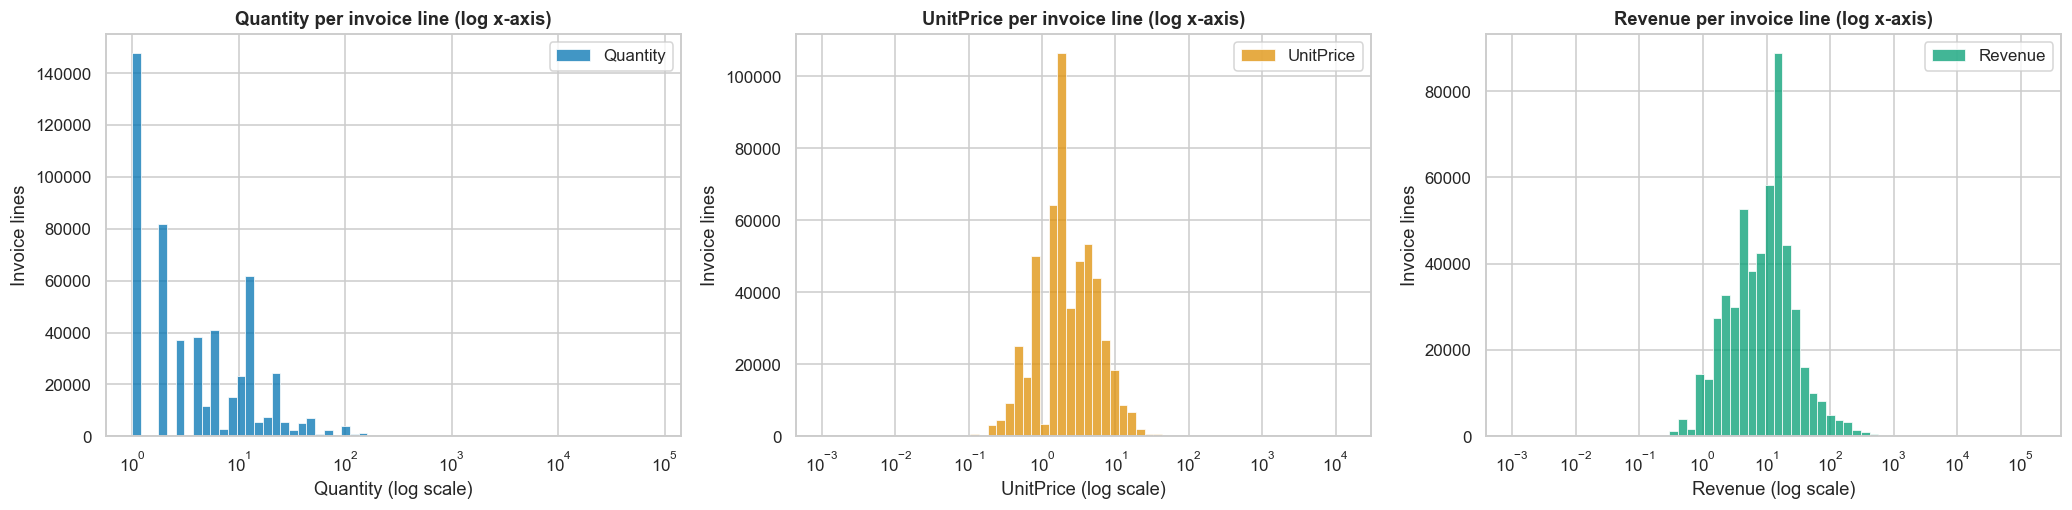

Skewness (raw scale): {'Quantity': 471.7, 'UnitPrice': 206.1, 'Revenue': 506.7}


In [5]:
sales = raw[(raw['Quantity'] > 0) & (raw['UnitPrice'] > 0)].copy()
sales['Revenue'] = sales['Quantity'] * sales['UnitPrice']

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, col, color in zip(axes, ['Quantity', 'UnitPrice', 'Revenue'], PALETTE):
    sns.histplot(sales[col], bins=60, log_scale=True, ax=ax, color=color, label=col)
    ax.set(title=f'{col} per invoice line (log x-axis)', xlabel=f'{col} (log scale)', ylabel='Invoice lines')
    ax.legend()
plt.tight_layout(); save_fig(fig, 'line_distributions'); plt.show()
print('Skewness (raw scale):', sales[['Quantity', 'UnitPrice', 'Revenue']].skew().round(1).to_dict())

**📝 Observations — invoice-line distributions**
- `Quantity`, `UnitPrice` and line revenue are all extremely right-skewed (skewness 200–500 on the raw scale). Most lines are a few units of £1–£5 items, but wholesale customers order thousands at once.
- On a log axis the distributions look roughly bell-shaped. Any customer-level spending feature built from these lines will be log-normal-like, which is why §3.3 log-transforms RFM before clustering.

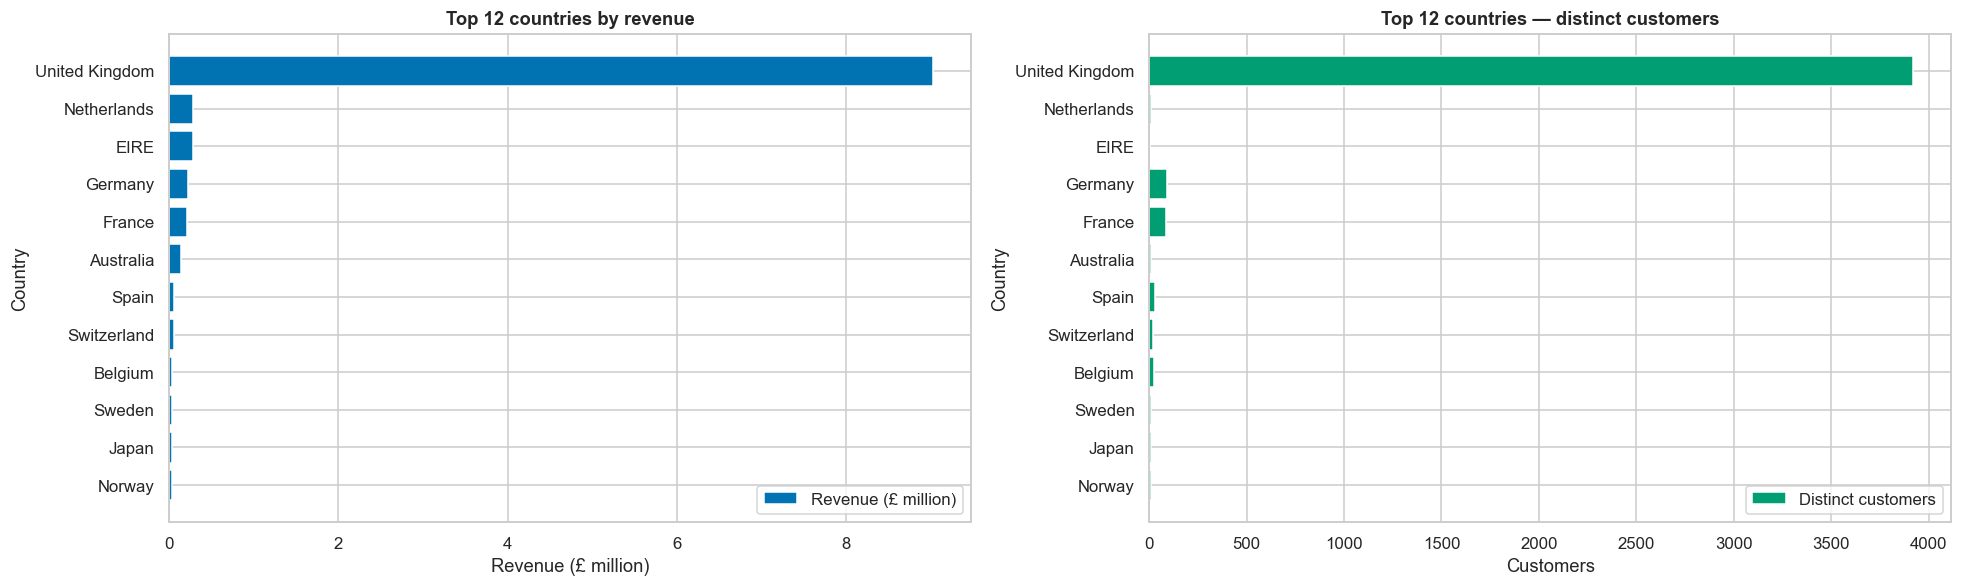

UK share of revenue: 84.6% | countries: 38


In [6]:
by_country = sales.groupby('Country').agg(lines=('InvoiceNo', 'size'), revenue=('Revenue', 'sum'),
                                          customers=('CustomerID', 'nunique')).sort_values('revenue', ascending=False)
top = by_country.head(12)
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
axes[0].barh(top.index[::-1], top['revenue'][::-1] / 1e6, color=PALETTE[0], label='Revenue (£ million)')
axes[0].set(title='Top 12 countries by revenue', xlabel='Revenue (£ million)', ylabel='Country')
axes[0].legend(loc='lower right')
axes[1].barh(top.index[::-1], top['customers'][::-1], color=PALETTE[2], label='Distinct customers')
axes[1].set(title='Top 12 countries — distinct customers', xlabel='Customers', ylabel='Country')
axes[1].legend(loc='lower right')
plt.tight_layout(); save_fig(fig, 'countries'); plt.show()
print(f"UK share of revenue: {by_country.loc['United Kingdom', 'revenue'] / by_country['revenue'].sum():.1%} | "
      f"countries: {len(by_country)}")

**📝 Observations — countries**
- The **United Kingdom generates 84.6 % of revenue** and most customers. The Netherlands, EIRE, Germany and France follow far behind.
- EIRE and the Netherlands have very few customers but high revenue, i.e. a handful of large wholesale buyers.
- Because the customer base is dominated by one country, `Country` is not used as a clustering feature (it would mostly separate UK vs non-UK). It is reported later only as a profiling descriptor.

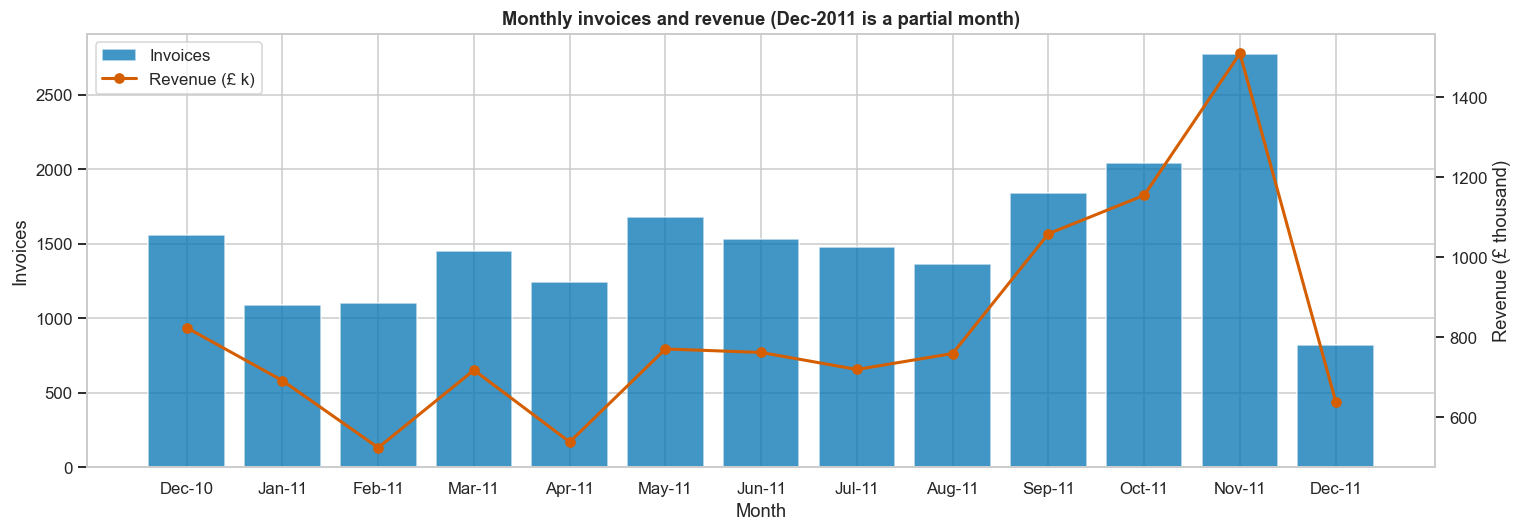

In [7]:
monthly = (sales.set_index('InvoiceDate').resample('MS')
           .agg({'Revenue': 'sum', 'InvoiceNo': 'nunique', 'CustomerID': 'nunique'}))
monthly.index = monthly.index.strftime('%b-%y')
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(monthly.index, monthly['InvoiceNo'], color=PALETTE[0], alpha=0.75, label='Invoices')
ax.set(title='Monthly invoices and revenue (Dec-2011 is a partial month)', xlabel='Month', ylabel='Invoices')
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(monthly.index, monthly['Revenue'] / 1e3, color=PALETTE[3], marker='o', lw=2, label='Revenue (£ k)')
ax2.set_ylabel('Revenue (£ thousand)')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout(); save_fig(fig, 'monthly_trend'); plt.show()

**📝 Observations — monthly trend**
- Invoices and revenue climb from late summer and **peak in November 2011** (Christmas stock-up by gift shops and wholesalers). December 2011 looks low only because the data stops on 9 December.
- This seasonality matters for **Recency**: a customer who last bought in early autumn may simply be waiting for the next season. Recency is still the standard "freshness" signal, but it should be read with the season in mind.

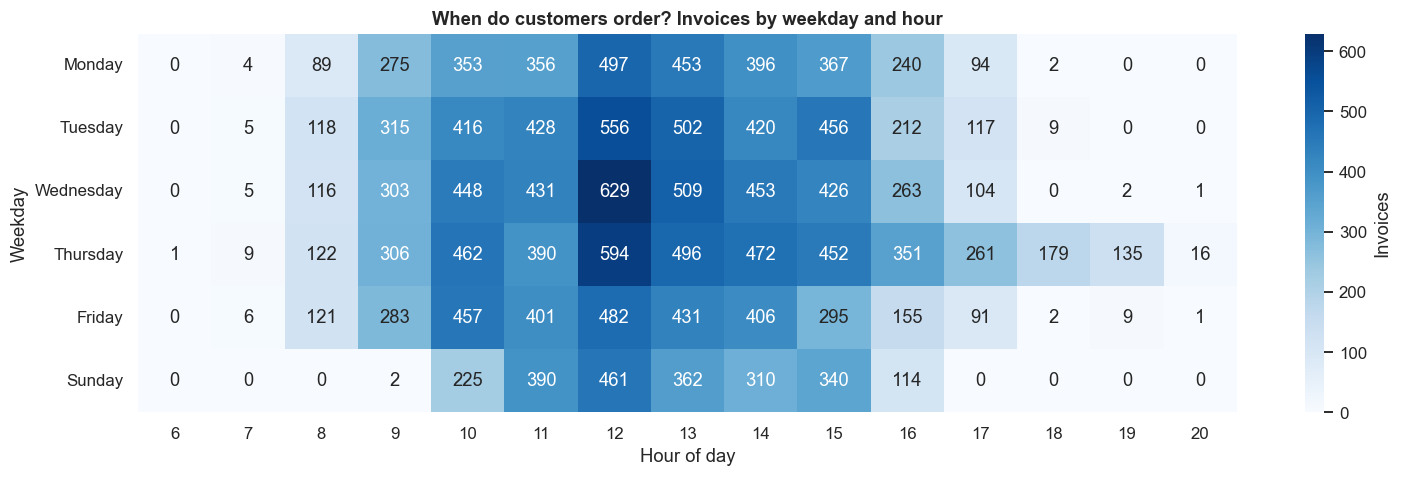

In [8]:
orders = sales.drop_duplicates('InvoiceNo')
heat = (orders.assign(day=orders['InvoiceDate'].dt.day_name(), hour=orders['InvoiceDate'].dt.hour)
        .pivot_table(index='day', columns='hour', values='InvoiceNo', aggfunc='count', fill_value=0)
        .reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).dropna(how='all'))
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(heat, cmap='Blues', annot=True, fmt='.0f', cbar_kws={'label': 'Invoices'}, ax=ax)
ax.set(title='When do customers order? Invoices by weekday and hour', xlabel='Hour of day', ylabel='Weekday')
plt.tight_layout(); save_fig(fig, 'weekday_hour'); plt.show()

**📝 Observations — ordering pattern**
- Orders arrive almost only during **office hours (about 08:00–17:00), peaking at 12:00**, from Monday to Friday plus a shorter Sunday window. There are **no Saturday orders at all**, and only Thursday has evening orders. This is a business-to-business pattern, which fits the dataset description: many customers are wholesalers and small gift shops, not consumers.
- This explains the very large `Quantity` values and why Frequency and Monetary vary over several orders of magnitude between customers.

---
## 3 · Cleaning & RFM feature engineering

### 3.1 Cleaning steps (each justified)

In [9]:
NON_PRODUCT_CODES = ['POST', 'DOT', 'M', 'C2', 'BANK CHARGES', 'PADS', 'CRUK', 'AMAZONFEE', 'B', 'S', 'D']

steps = [('Raw transaction lines', raw)]
tx = raw.dropna(subset=['CustomerID'])
steps.append(('Drop lines without CustomerID (cannot be assigned to a customer)', tx))
tx = tx[~tx['InvoiceNo'].str.startswith('C')]
steps.append(('Drop cancelled invoices (InvoiceNo starts with "C")', tx))
tx = tx[(tx['Quantity'] > 0) & (tx['UnitPrice'] > 0)]
steps.append(('Drop non-positive quantity / price (returns, adjustments)', tx))
tx = tx[~tx['StockCode'].str.upper().isin(NON_PRODUCT_CODES)]
steps.append(('Drop non-product codes (postage, manual, bank charges, …)', tx))
tx = tx.drop_duplicates()
steps.append(('Drop exact duplicate lines', tx))

log = pd.DataFrame([{'step': s, 'rows': len(d), 'customers': d['CustomerID'].nunique()} for s, d in steps])
log['rows_removed'] = (-log['rows'].diff()).fillna(0).astype(int)
display(log.set_index('step'))

tx = tx.assign(CustomerID=tx['CustomerID'].astype(int), Revenue=tx['Quantity'] * tx['UnitPrice'])
print(f'Clean transaction lines: {len(tx):,} | customers: {tx["CustomerID"].nunique():,}')

,rows,customers,rows_removed
step,,,
Raw transaction lines,541909,4372,0
Drop lines without CustomerID (cannot be assigned to a customer),406829,4372,135080
"Drop cancelled invoices (InvoiceNo starts with ""C"")",397924,4339,8905
"Drop non-positive quantity / price (returns, adjustments)",397884,4338,40
"Drop non-product codes (postage, manual, bank charges, …)",396337,4334,1547
Drop exact duplicate lines,391150,4334,5187


Clean transaction lines: 391,150 | customers: 4,334


**📝 Observations — cleaning**
- 135,080 anonymous lines are removed first. They cannot be attributed to a customer.
- Cancelled invoices (8,905 lines after the first step) and 40 zero-price lines are removed, because RFM must describe what customers actually **bought**.
- 1,547 lines with **non-product stock codes** (postage `POST`, `DOT` postage, manual adjustments `M`, bank charges, carriage `C2`, Amazon fees, …) are removed. They are service charges, not purchases, and would inflate Monetary for customers who pay postage.
- 5,187 exact duplicate lines are removed.
- **Result: 391,150 clean lines for 4,334 customers** (only 38 customers are lost, all of whom only had cancellations or charges).

### 3.2 Feature engineering — RFM per customer

| Feature | Definition | Business meaning |
|---------|-----------|------------------|
| **Recency** | whole days between the customer's last invoice date and the snapshot date (the day after the last invoice in the data, so a purchase on the final day = 1) | how *recently* they bought — low is good |
| **Frequency** | number of distinct invoices | how *often* they buy |
| **Monetary** | total spend (£) | how *much* they are worth |

RFM is the standard, interpretable representation for customer-value segmentation: three numbers summarise thousands
of invoice lines. Three extra descriptors (`AvgBasketValue`, `Tenure`, `UniqueProducts`) are computed **for profiling
only** — they are *not* clustering inputs, which keeps the clusters easy to explain.

In [10]:
SNAPSHOT = tx['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)


def build_rfm(transactions, snapshot):
    """Aggregate clean transaction lines into one RFM row per customer (+ profiling descriptors)."""
    g = transactions.groupby('CustomerID')
    out = pd.DataFrame({
        'Recency': (snapshot - g['InvoiceDate'].max().dt.normalize()).dt.days,
        'Frequency': g['InvoiceNo'].nunique(),
        'Monetary': g['Revenue'].sum(),
        'Tenure': (snapshot - g['InvoiceDate'].min().dt.normalize()).dt.days,
        'UniqueProducts': g['StockCode'].nunique(),
        'Country': g['Country'].agg(lambda s: s.mode().iat[0]),
    })
    out['AvgBasketValue'] = out['Monetary'] / out['Frequency']
    return out


rfm = build_rfm(tx, SNAPSHOT)
RFM = ['Recency', 'Frequency', 'Monetary']
print(f'Snapshot date: {SNAPSHOT:%d-%b-%Y} | customers: {len(rfm):,}')
display(rfm.head())
display(rfm[RFM + ['AvgBasketValue', 'Tenure', 'UniqueProducts']].describe().T.round(2))

Snapshot date: 10-Dec-2011 | customers: 4,334


,Recency,Frequency,Monetary,Tenure,UniqueProducts,Country,AvgBasketValue
CustomerID,,,,,,,
12346,326,1,77183.60,326,1,United Kingdom,77183.600000
12347,3,7,4310.00,368,103,Iceland,615.714286
12348,76,4,1437.24,359,21,Finland,359.310000
12349,19,1,1457.55,19,72,Italy,1457.550000
12350,311,1,294.40,311,16,Norway,294.400000


,count,mean,std,min,25%,50%,75%,max
Recency,4334.0,93.23,100.18,1.00,18.00,51.00,143.00,374.00
Frequency,4334.0,4.25,7.63,1.00,1.00,2.00,5.00,206.00
Monetary,4334.0,2015.97,8903.67,3.75,304.24,662.56,1631.62,279138.02
AvgBasketValue,4334.0,415.48,1800.90,3.75,177.20,289.56,423.41,84236.25
Tenure,4334.0,223.83,117.84,1.00,113.00,249.00,327.00,374.00
UniqueProducts,4334.0,61.43,85.31,1.00,16.00,35.00,77.00,1785.00


### 3.3 Skewness → log transform

,skew_raw,skew_after_log1p
Recency,1.24,-0.33
Frequency,11.95,1.21
Monetary,19.58,0.40


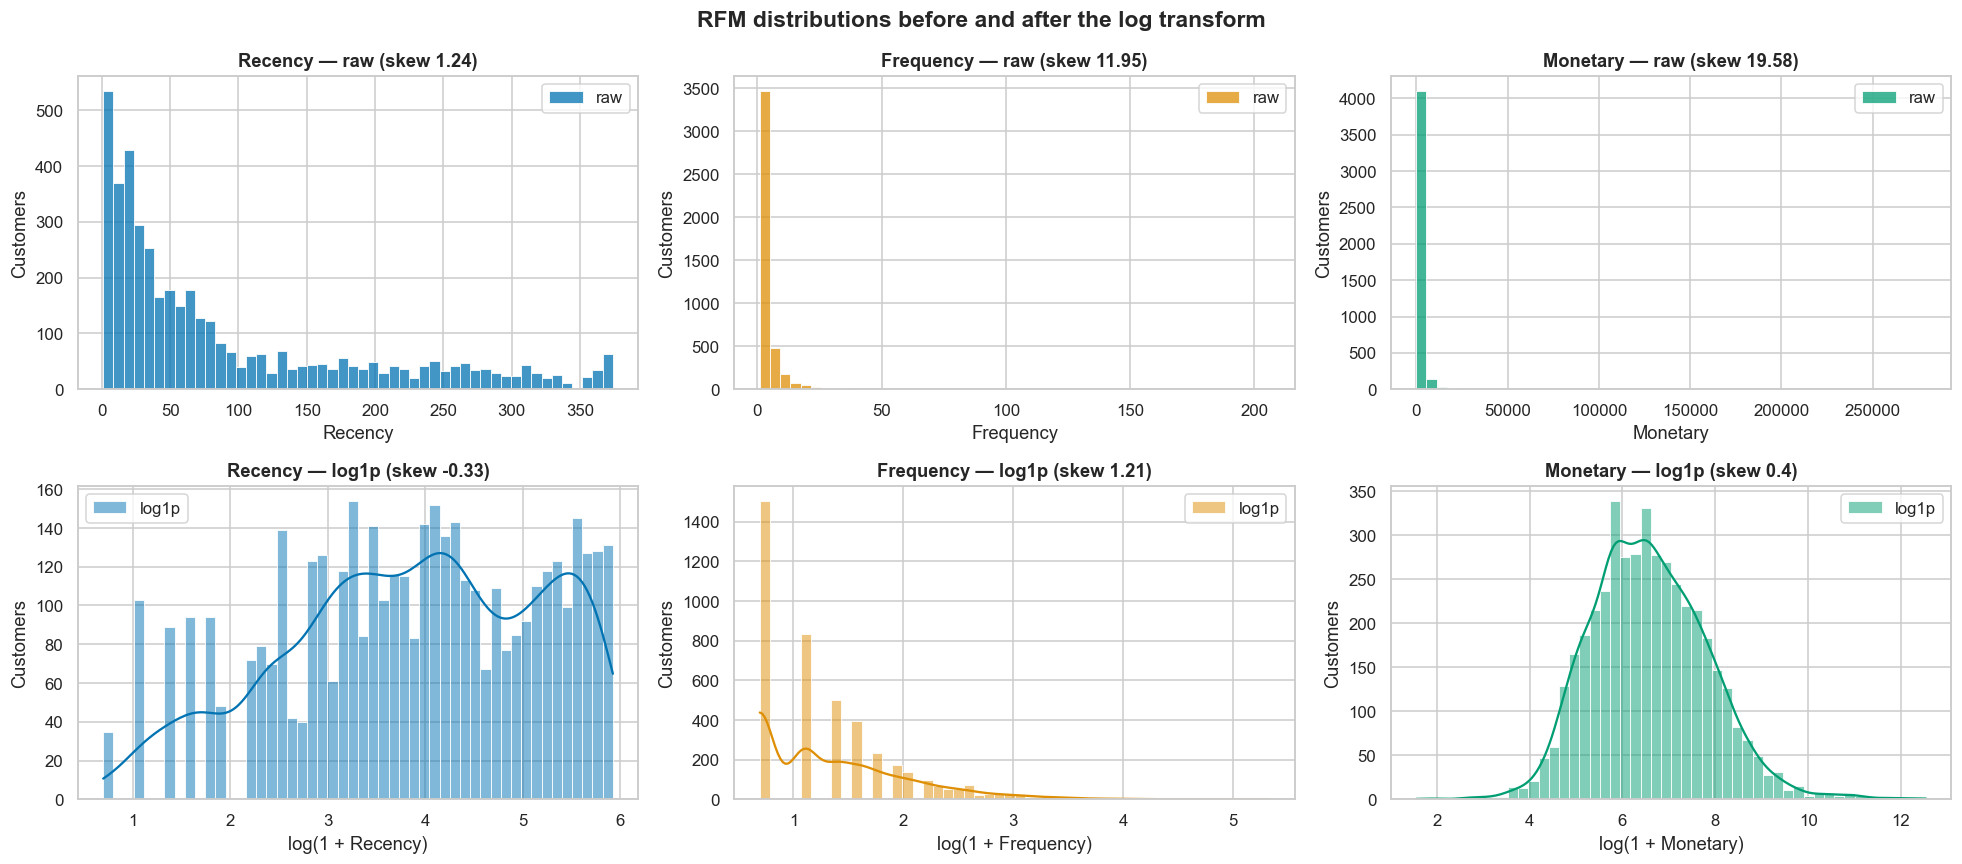

In [11]:
rfm_log = np.log1p(rfm[RFM])
skew_tbl = pd.DataFrame({'skew_raw': rfm[RFM].skew(), 'skew_after_log1p': rfm_log.skew()}).round(2)
display(skew_tbl)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for i, col in enumerate(RFM):
    sns.histplot(rfm[col], bins=50, ax=axes[0, i], color=PALETTE[i], label='raw')
    axes[0, i].set(title=f'{col} — raw (skew {skew_tbl.loc[col, "skew_raw"]})', xlabel=col, ylabel='Customers')
    sns.histplot(rfm_log[col], bins=50, ax=axes[1, i], color=PALETTE[i], kde=True, label='log1p')
    axes[1, i].set(title=f'{col} — log1p (skew {skew_tbl.loc[col, "skew_after_log1p"]})',
                   xlabel=f'log(1 + {col})', ylabel='Customers')
    axes[0, i].legend(); axes[1, i].legend()
fig.suptitle('RFM distributions before and after the log transform', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'rfm_distributions'); plt.show()

**📝 Observations — skewness and the log transform**
- Raw RFM is very skewed: **Frequency skew 11.95, Monetary skew 19.58**. One customer spent £279,138 while the median spends £663. K-Means minimises squared Euclidean distance, so on the raw scale a few extreme customers would dominate the centroids and almost everyone else would fall into one big cluster.
- After `log1p`, Monetary skew drops to 0.40 and Frequency to 1.21 (Frequency stays somewhat skewed because 35 % of customers bought exactly once). Recency becomes mildly left-skewed (−0.33).
- The log transform also matches business intuition: going from 1 to 2 orders is a bigger behavioural change than going from 101 to 102.

### 3.4 Outliers, correlation and scaling

Customers with |z| > 3 on the log scale: {'Recency': 0, 'Frequency': 46, 'Monetary': 38}


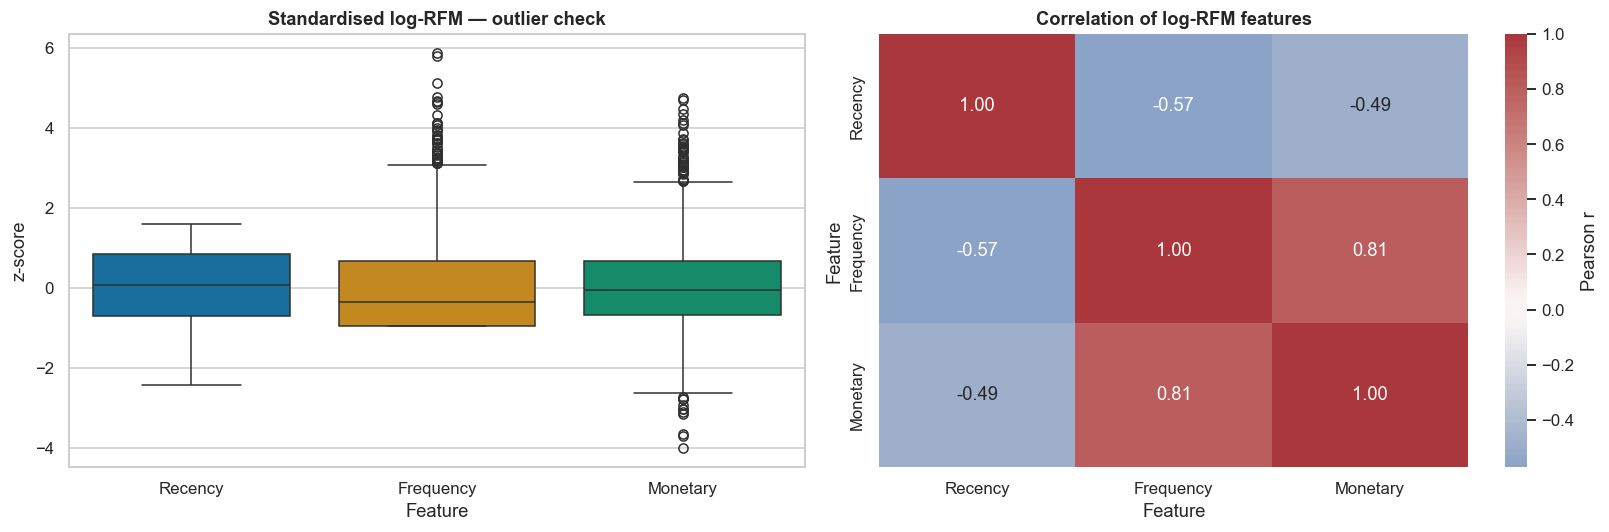

In [12]:
z = (rfm_log - rfm_log.mean()) / rfm_log.std()
print('Customers with |z| > 3 on the log scale:', {c: int((z[c].abs() > 3).sum()) for c in RFM})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=z, ax=axes[0], palette='colorblind')
axes[0].set(title='Standardised log-RFM — outlier check', xlabel='Feature', ylabel='z-score')
sns.heatmap(rfm_log.corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[1],
            cbar_kws={'label': 'Pearson r'})
axes[1].set(title='Correlation of log-RFM features', xlabel='Feature', ylabel='Feature')
plt.tight_layout(); save_fig(fig, 'outliers_corr'); plt.show()

In [13]:
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)          # clustering input: log1p + standardisation
X_df = pd.DataFrame(X, columns=RFM, index=rfm.index)
display(X_df.describe().T[['mean', 'std', 'min', 'max']].round(3))

,mean,std,min,max
Recency,-0.0,1.0,-2.421,1.582
Frequency,0.0,1.0,-0.951,5.855
Monetary,0.0,1.0,-3.998,4.753


**📝 Observations — outliers, correlation, scaling**
- After the log transform only 46 customers (Frequency) and 38 (Monetary) have |z| > 3, and none for Recency. The high ones are genuine top wholesale buyers and the few low Monetary ones are customers who bought a single cheap item. Neither are errors, so all are **kept**: the high outliers form the core of the most valuable segment, and removing them would hide exactly the customers the business cares about most.
- log-Frequency and log-Monetary are strongly correlated (**r = 0.81**): customers who order more often spend more. Recency is negatively correlated with both (−0.57, −0.49). The three features are related but not redundant.
- `StandardScaler` gives each feature mean 0 and standard deviation 1, so days, order counts and pounds contribute equally to the Euclidean distance.
- *Why no train/test split?* Clustering has no labels to predict, so there is no held-out error to estimate. Every customer is segmented, and quality is judged with internal metrics (§6).

---
## 4 · K-Means clustering

K-Means places `k` centroids and alternately (i) assigns every customer to the nearest centroid and (ii) moves each
centroid to the mean of its customers, minimising the **within-cluster sum of squares (inertia)**.
`init='k-means++'` spreads the initial centroids and `n_init=20` keeps the best of 20 restarts.

### 4.1 Elbow curve and metric sweep (k = 2 … 10)

In [14]:
K_RANGE = range(2, 11)
sweep = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X)
    sweep.append({'k': k, 'Inertia': km.inertia_, **cluster_metrics(X, km.labels_),
                  'Smallest cluster %': np.bincount(km.labels_).min() / len(X) * 100})
sweep = pd.DataFrame(sweep).set_index('k')


def knee_point(x, y):
    """Kneedle-style elbow: the point farthest from the straight line joining the curve's end points."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
    dist = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return int(x[np.argmax(dist)])


ELBOW_K = knee_point(sweep.index, sweep['Inertia'])
display(sweep.style.format({'Inertia': '{:,.1f}', 'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}',
                            'Calinski-Harabasz': '{:,.1f}', 'Smallest cluster %': '{:.1f}'})
        .highlight_max(subset=['Silhouette', 'Calinski-Harabasz'], color='#c7e9c0')
        .highlight_min(subset=['Davies-Bouldin'], color='#c7e9c0'))
print(f'Elbow (knee) of the inertia curve: k = {ELBOW_K}')

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %
k,,,,,
2,"6,469.8",0.4328,0.8904,"4,373.8",38.3
3,"4,850.1",0.3382,1.0411,"3,639.8",17.4
4,"3,918.8",0.3361,1.0177,"3,345.4",16.1
5,"3,262.4",0.3182,0.9829,"3,231.0",8.3
6,"2,835.9",0.3134,1.0138,"3,103.0",7.8
7,"2,528.0",0.3041,0.9892,"2,987.9",5.0
8,"2,326.7",0.2970,1.0150,"2,835.6",4.3
9,"2,146.6",0.2809,1.0215,"2,734.0",4.9
10,"1,987.7",0.2768,1.0276,"2,662.3",2.2


Elbow (knee) of the inertia curve: k = 5


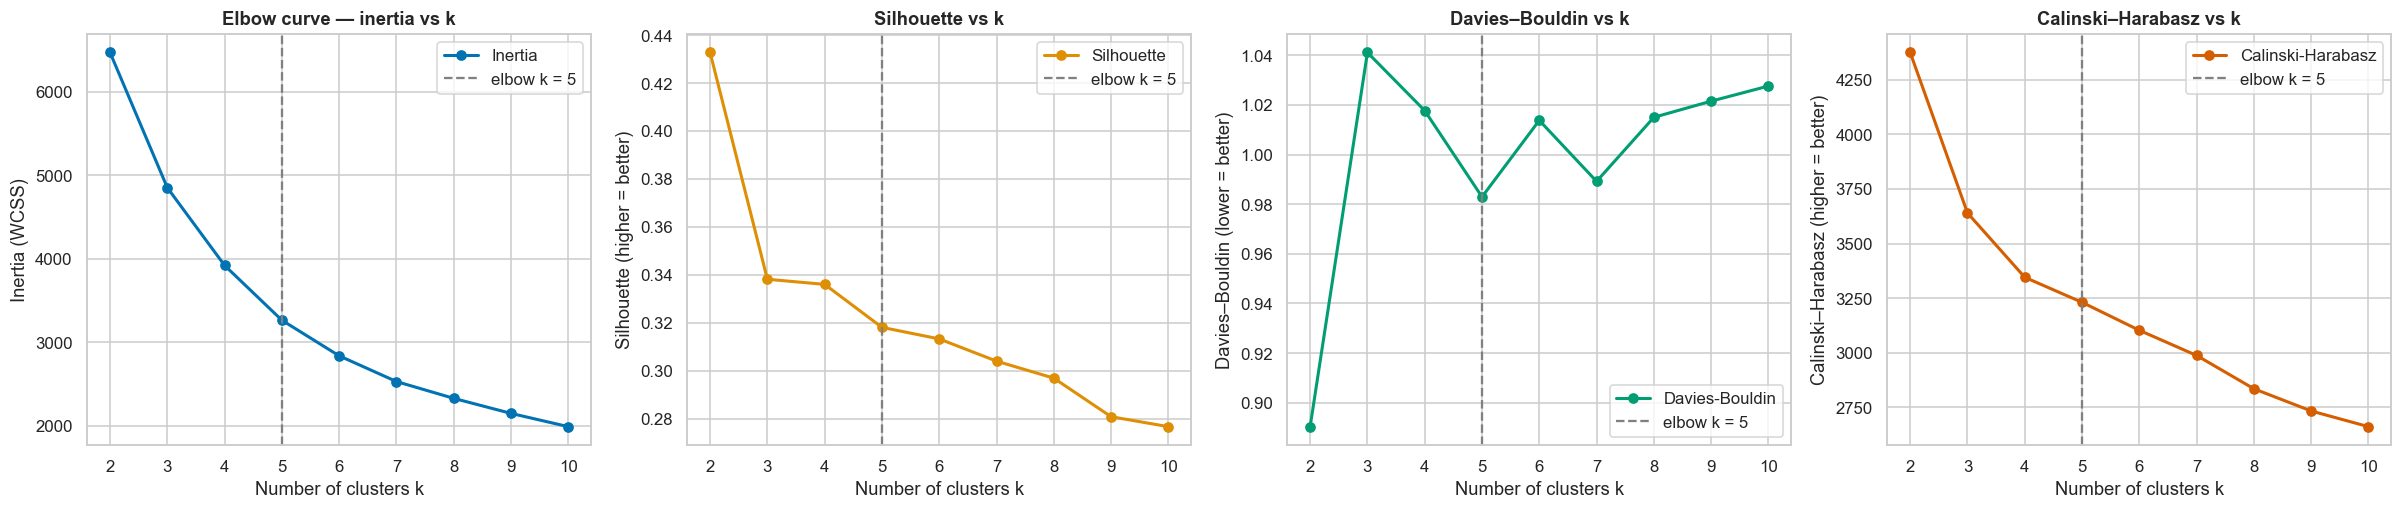

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
specs = [('Inertia', 'Inertia (WCSS)', 'Elbow curve — inertia vs k'),
         ('Silhouette', 'Silhouette (higher = better)', 'Silhouette vs k'),
         ('Davies-Bouldin', 'Davies–Bouldin (lower = better)', 'Davies–Bouldin vs k'),
         ('Calinski-Harabasz', 'Calinski–Harabasz (higher = better)', 'Calinski–Harabasz vs k')]
for ax, (col, ylabel, title), color in zip(axes, specs, PALETTE):
    ax.plot(sweep.index, sweep[col], marker='o', color=color, lw=2, label=col)
    ax.axvline(ELBOW_K, ls='--', color='grey', label=f'elbow k = {ELBOW_K}')
    ax.set(title=title, xlabel='Number of clusters k', ylabel=ylabel, xticks=list(K_RANGE))
    ax.legend()
plt.tight_layout(); save_fig(fig, 'elbow_metrics'); plt.show()

**📝 Choosing k**
- **Elbow curve:** inertia falls steeply from k = 2 to 5 and flattens afterwards. The knee detector (point farthest from the chord joining the curve's ends) places the elbow at **k = 5**.
- **Silhouette** is highest at k = 2 (0.433), drops to about 0.34 at k = 3–4 and declines slowly to 0.32 at k = 5. A 2-cluster split only says "good customers vs the rest", which is too coarse to act on.
- **Davies–Bouldin** has a **local minimum at k = 5 (0.983)**, lower than k = 3, 4 or 6 (1.04, 1.02, 1.01). The 5 clusters are better separated relative to their size than neighbouring choices.
- **Business check:** at k = 4 the very best customers are merged with the regular loyal buyers. At k = 5 they separate into their own small group that holds more than half of revenue (§8). That is the most useful segment for the business.
- **Decision: k = 5.** It is at the elbow, at a Davies–Bouldin minimum, and gives segments that are distinct and actionable. Its silhouette (≈ 0.32) is in the usual "reasonable structure" range for real behavioural data, where customers form a continuum rather than isolated blobs.

### 4.2 Final K-Means model

In [16]:
OPTIMAL_K = ELBOW_K
kmeans = KMeans(n_clusters=OPTIMAL_K, init='k-means++', n_init=20, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_

centroids = pd.DataFrame(np.expm1(scaler.inverse_transform(kmeans.cluster_centers_)), columns=RFM).round(1)
centroids['customers'] = np.bincount(km_labels)
centroids['share_%'] = (centroids['customers'] / len(X) * 100).round(1)
centroids.index.name = 'K-Means cluster'
print(f'K-Means (k={OPTIMAL_K}) converged in {kmeans.n_iter_} iterations; inertia = {kmeans.inertia_:,.1f}')
display(centroids)

K-Means (k=5) converged in 15 iterations; inertia = 3,262.4


,Recency,Frequency,Monetary,customers,share_%
K-Means cluster,,,,,
0,7.8,16.7,7212.8,358,8.3
1,194.6,1.2,220.3,1136,26.2
2,14.0,5.3,1720.0,965,22.3
3,24.0,1.5,310.8,869,20.1
4,89.7,2.8,1054.4,1006,23.2


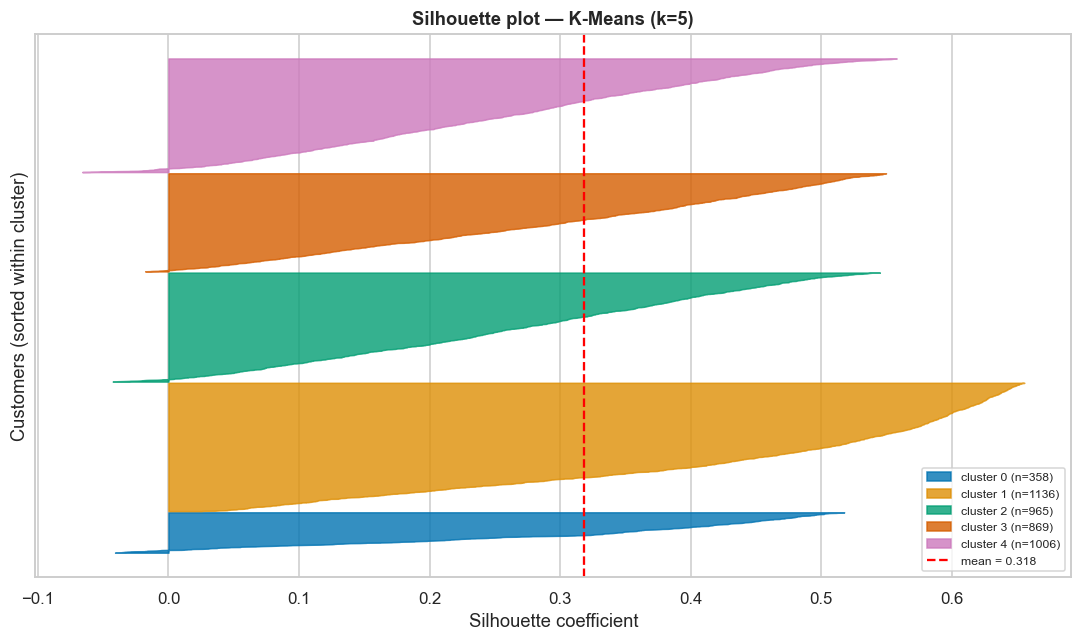

Customers with a negative silhouette (probably mis-assigned): 91 (2.1%)


In [17]:
def silhouette_plot(ax, X, labels, title):
    """Per-customer silhouette values, grouped and sorted by cluster."""
    sil = silhouette_samples(X, labels)
    y_lower = 10
    for c in np.unique(labels):
        vals = np.sort(sil[labels == c])
        ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, color=PALETTE[c], alpha=0.8,
                         label=f'cluster {c} (n={len(vals)})')
        y_lower += len(vals) + 10
    ax.axvline(sil.mean(), color='red', ls='--', label=f'mean = {sil.mean():.3f}')
    ax.set(title=title, xlabel='Silhouette coefficient', ylabel='Customers (sorted within cluster)', yticks=[])
    ax.legend(loc='lower right', fontsize=8)
    return sil


fig, ax = plt.subplots(figsize=(10, 6))
km_sil = silhouette_plot(ax, X, km_labels, f'Silhouette plot — K-Means (k={OPTIMAL_K})')
plt.tight_layout(); save_fig(fig, 'silhouette_kmeans'); plt.show()
print(f'Customers with a negative silhouette (probably mis-assigned): {(km_sil < 0).sum()} ({(km_sil < 0).mean():.1%})')

**📝 Observations — final K-Means model**
- K-Means converged in 15 iterations. The centroids (back-transformed to original units) are clearly different customer types, ranging from **358 customers who bought ~17 times for ~£7,200 within the last ~8 days** to **1,136 customers who bought once, ~195 days ago, for ~£220**.
- **Silhouette plot:** every cluster has a mean silhouette above zero, and only **91 customers (2.1 %) have a negative silhouette**, i.e. sit closer to a neighbouring cluster. These are border-line customers between adjacent segments, which is expected because behaviour is continuous.
- Cluster sizes range from 8 % to 26 % of customers, so no cluster is degenerate.

---
## 5 · Agglomerative hierarchical clustering

Starts with every customer as its own cluster and repeatedly **merges the two closest clusters**; the *linkage* rule
defines "closest":

| Linkage | Distance between two clusters | Typical behaviour |
|---------|-------------------------------|-------------------|
| **Ward** | increase in total within-cluster variance after merging | compact, similar-sized clusters (same objective as K-Means) |
| **Complete** | largest pairwise distance | compact clusters, sensitive to outliers |
| **Average** | mean pairwise distance | between single and complete |
| **Single** | smallest pairwise distance | "chaining" — long, straggly clusters |

### 5.1 Dendrogram (Ward linkage, all customers)

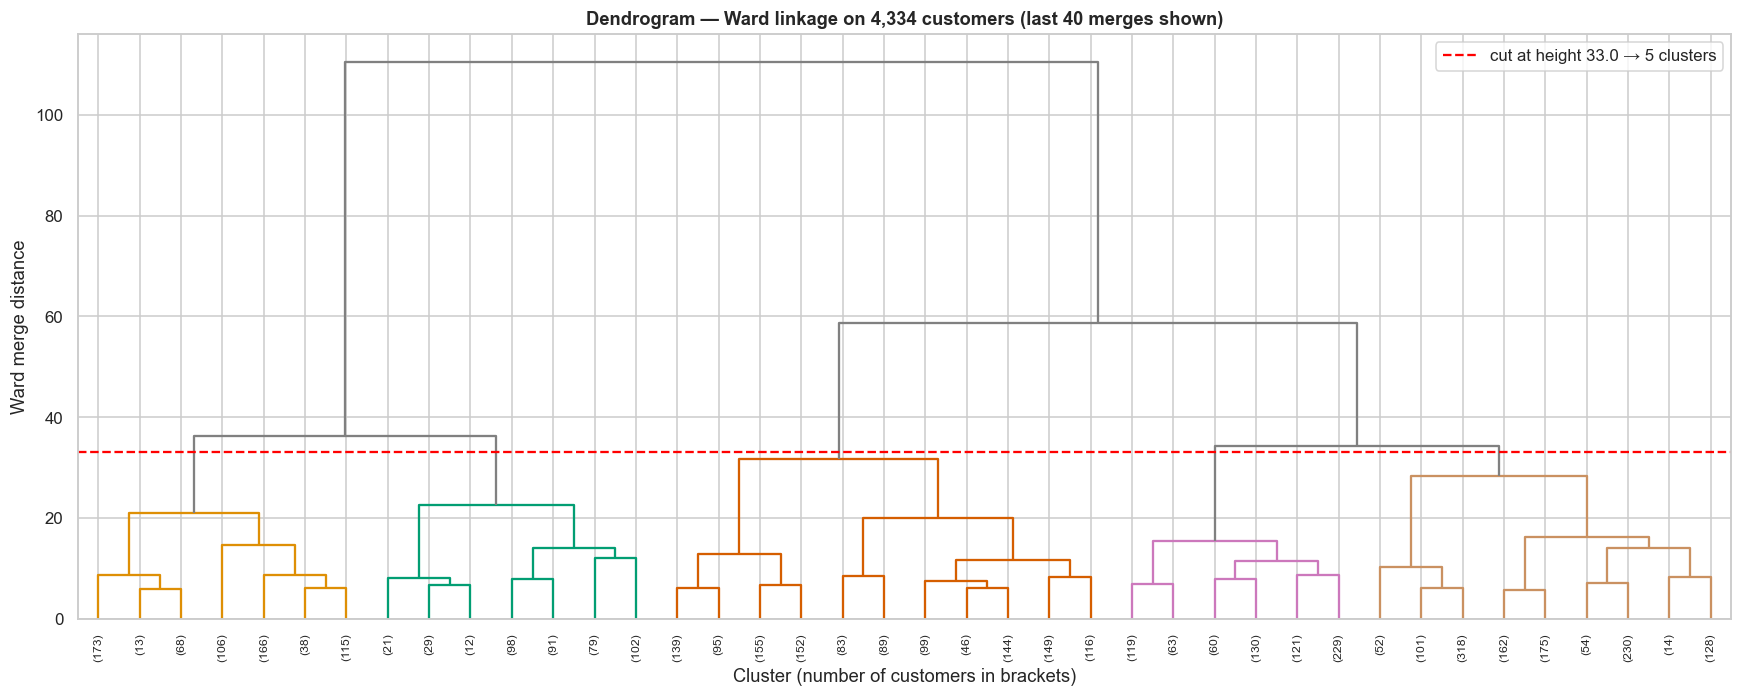

Largest jumps in merge distance (top of the tree):
  going from 2 to 1 clusters costs a merge-distance jump of   51.89
  going from 3 to 2 clusters costs a merge-distance jump of   22.53
  going from 4 to 3 clusters costs a merge-distance jump of    1.95
  going from 5 to 4 clusters costs a merge-distance jump of    2.44
  going from 6 to 5 clusters costs a merge-distance jump of    3.42
  going from 7 to 6 clusters costs a merge-distance jump of    5.81
  going from 8 to 7 clusters costs a merge-distance jump of    1.53
  going from 9 to 8 clusters costs a merge-distance jump of    1.14
  going from 10 to 9 clusters costs a merge-distance jump of    3.78


In [18]:
Z = {m: linkage(X, method=m) for m in ['ward', 'complete', 'average', 'single']}


def cut_height(Zm, k):
    """Height at which a horizontal cut of the dendrogram yields exactly k clusters."""
    return (Zm[-k, 2] + Zm[-(k - 1), 2]) / 2


fig, ax = plt.subplots(figsize=(16, 6.5))
h = cut_height(Z['ward'], OPTIMAL_K)
dendrogram(Z['ward'], truncate_mode='lastp', p=40, show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=8, color_threshold=h, above_threshold_color='grey', ax=ax)
ax.axhline(h, color='red', ls='--', lw=1.5, label=f'cut at height {h:.1f} → {OPTIMAL_K} clusters')
ax.set(title=f'Dendrogram — Ward linkage on {len(X):,} customers (last 40 merges shown)',
       xlabel='Cluster (number of customers in brackets)', ylabel='Ward merge distance')
ax.legend()
plt.tight_layout(); save_fig(fig, 'dendrogram_ward'); plt.show()

gaps = np.diff(Z['ward'][-10:, 2])[::-1]
print('Largest jumps in merge distance (top of the tree):')
for k, g in zip(range(2, 11), gaps):
    print(f'  going from {k} to {k - 1} clusters costs a merge-distance jump of {g:7.2f}')

**📝 Observations — dendrogram**
- The dendrogram is built bottom-up from all 4,334 customers. Ward linkage merges the pair of clusters whose union increases within-cluster variance the least, the same objective that K-Means minimises.
- The **largest vertical gaps are at the top**: merging 3 clusters into 2 costs a distance jump of 22.5, and merging 2 into 1 costs 51.9. Ward therefore sees **2–3 very broad groups** in the data (recent/active vs lapsed customers).
- The red line cuts the tree at height ≈ 33, which gives **5 clusters** for a direct comparison with K-Means. Below the line the merge jumps are small (≈ 2–6), so the exact number of fine-grained segments is a judgement call. The dendrogram supports k = 5 as a sub-division of the 2–3 natural groups, not as an obvious natural cut.

### 5.2 Comparing linkage strategies

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes,Largest cluster %
Linkage,,,,,
ward,0.2226,1.3071,"2,505.4","1267, 1234, 722, 679, 432",29.2
complete,0.0950,0.8629,696.4,"3707, 412, 181, 30, 4",85.5
average,0.3899,0.6326,"1,196.3","2680, 1620, 30, 3, 1",61.8
single,0.4215,0.4062,11.4,"4328, 3, 1, 1, 1",99.9


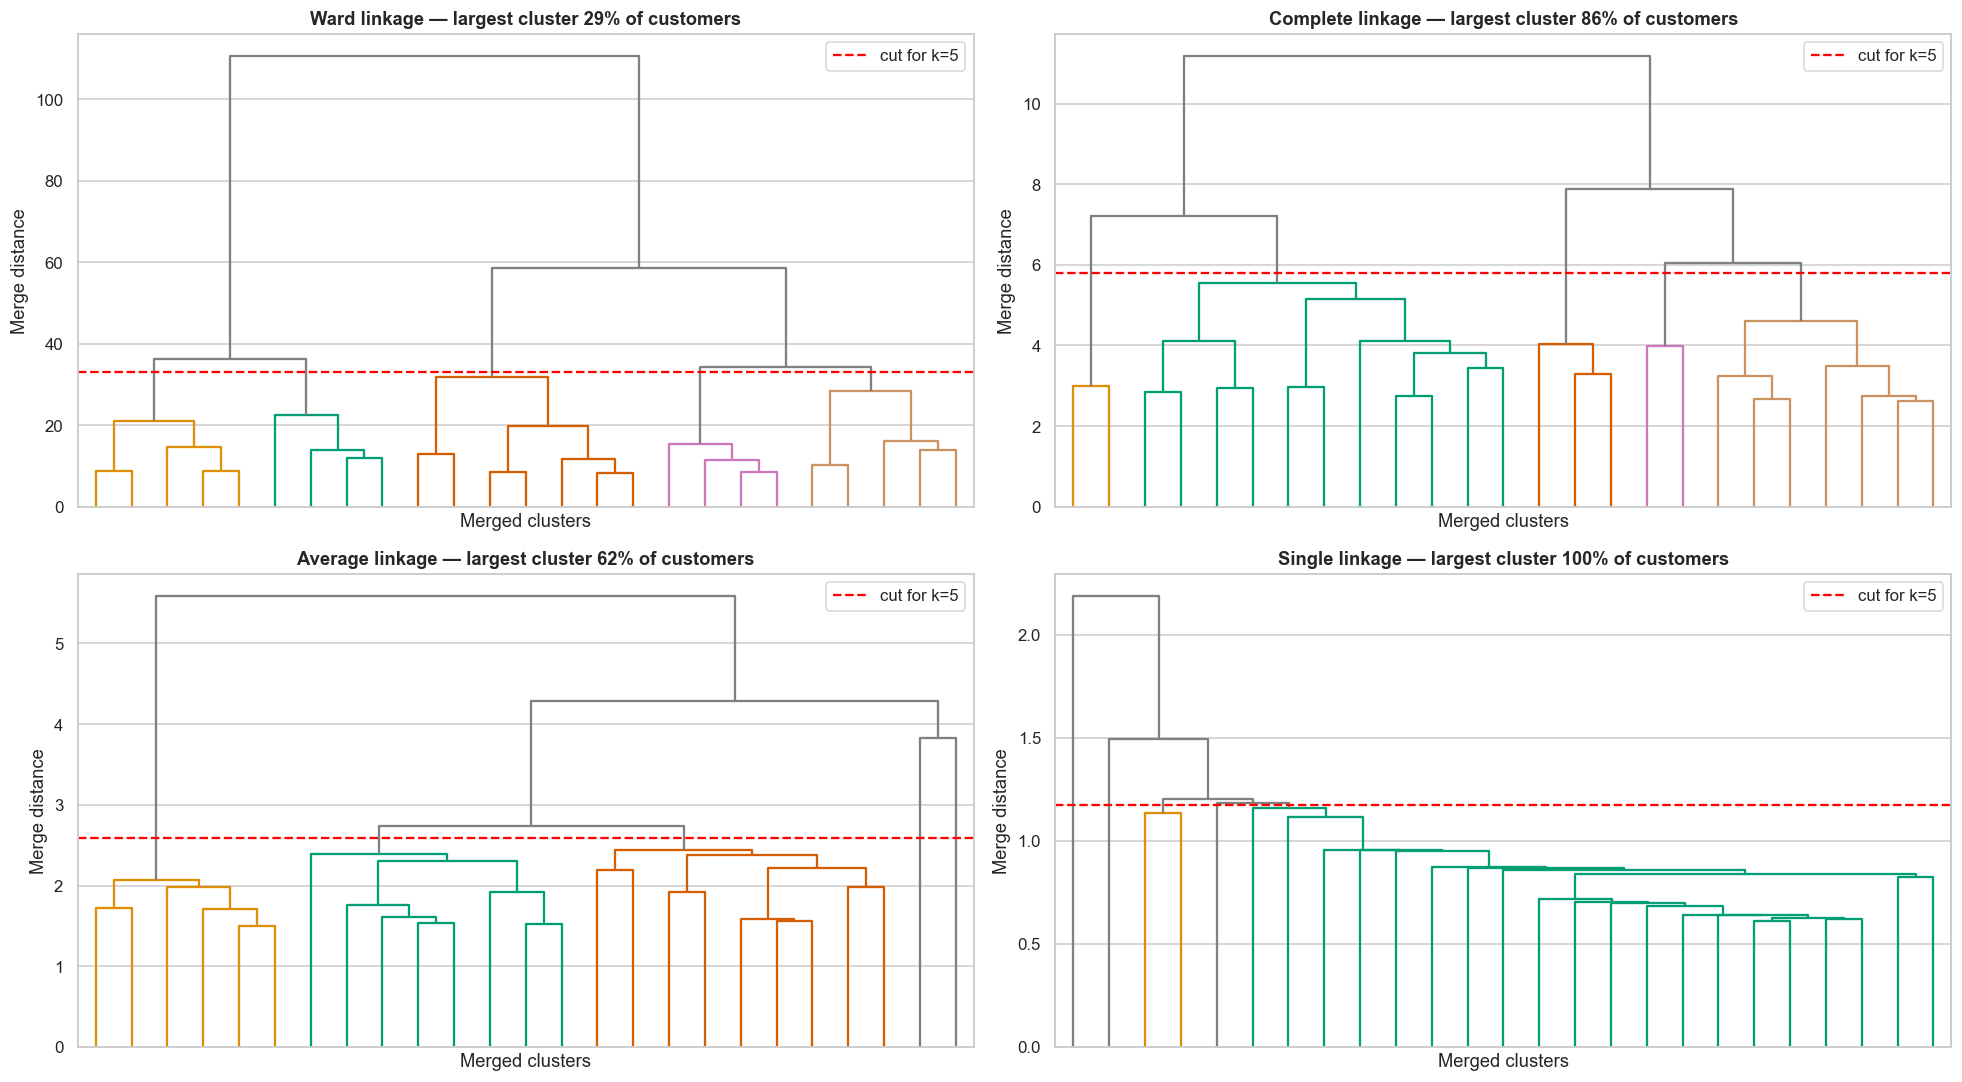

In [19]:
link_rows = []
for m in Z:
    labels = AgglomerativeClustering(n_clusters=OPTIMAL_K, linkage=m).fit_predict(X)
    sizes = np.bincount(labels)
    link_rows.append({'Linkage': m, **cluster_metrics(X, labels),
                      'Cluster sizes': ', '.join(map(str, sorted(sizes, reverse=True))),
                      'Largest cluster %': sizes.max() / len(X) * 100})
link_df = pd.DataFrame(link_rows).set_index('Linkage')
display(link_df.style.format({'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}', 'Calinski-Harabasz': '{:,.1f}',
                              'Largest cluster %': '{:.1f}'}))

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for ax, m in zip(axes.flat, Z):
    hm = cut_height(Z[m], OPTIMAL_K)
    dendrogram(Z[m], truncate_mode='lastp', p=25, no_labels=True, color_threshold=hm,
               above_threshold_color='grey', ax=ax)
    ax.axhline(hm, color='red', ls='--', label=f'cut for k={OPTIMAL_K}')
    ax.set(title=f"{m.title()} linkage — largest cluster {link_df.loc[m, 'Largest cluster %']:.0f}% of customers",
           xlabel='Merged clusters', ylabel='Merge distance')
    ax.legend()
plt.tight_layout(); save_fig(fig, 'dendrogram_linkages'); plt.show()

**📝 Observations — linkage comparison (k = 5)**

| Linkage | What happens |
|---------|-------------|
| **Single** | highest silhouette (0.42) and lowest DB (0.41), but **one cluster holds 99.9 % of customers** and the other four have 1–3 customers each. This is the *chaining effect*: single linkage just peels off outliers. |
| **Average** | silhouette 0.39 but again lopsided (62 % / 37 % plus three tiny clusters). |
| **Complete** | very unbalanced (86 % in one cluster) and the worst silhouette (0.10). |
| **Ward** | the **only balanced partition** (10–29 % per cluster) and by far the highest Calinski–Harabasz (2,505). |

**Lesson for evaluation:** a good silhouette or Davies–Bouldin score can be produced by a *useless* clustering that isolates a few outliers. Metrics must be read together with cluster sizes. **Ward is chosen** because it is the only linkage that produces usable segments, and because it optimises the same variance objective as K-Means, which makes the comparison fair.

### 5.3 Final hierarchical model (Ward)

In [20]:
agg = AgglomerativeClustering(n_clusters=OPTIMAL_K, linkage='ward')
agg_raw = agg.fit_predict(X)

# Agglomerative cluster ids are arbitrary: relabel them to the K-Means cluster they overlap most with,
# so that "cluster 0" means the same kind of customer in both models (pure renaming, metrics unchanged)
overlap = pd.crosstab(agg_raw, km_labels)
mapping, used = {}, set()
for a in overlap.max(axis=1).sort_values(ascending=False).index:
    b = next(c for c in overlap.loc[a].sort_values(ascending=False).index if c not in used)
    mapping[a] = b; used.add(b)
agg_labels = np.vectorize(mapping.get)(agg_raw)

print(f'Agglomerative (Ward, k={OPTIMAL_K}) cluster sizes:', np.bincount(agg_labels).tolist())
print(f'K-Means                     cluster sizes:', np.bincount(km_labels).tolist())

Agglomerative (Ward, k=5) cluster sizes: [432, 1234, 679, 722, 1267]
K-Means                     cluster sizes: [358, 1136, 965, 869, 1006]


---
## 6 · Evaluation — mandatory internal metrics

| Metric | Measures | Range | Better |
|--------|----------|-------|--------|
| **Silhouette** | how much closer a customer is to its own cluster than to the next one | −1 … 1 | higher |
| **Davies–Bouldin** | average similarity of each cluster with its most similar cluster | 0 … ∞ | lower |
| **Calinski–Harabasz** | between-cluster dispersion ÷ within-cluster dispersion | 0 … ∞ | higher |

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes
Algorithm,,,,
"K-Means (k=5, k-means++)",0.3182,0.9829,"3,231.0","358, 1136, 965, 869, 1006"
"Agglomerative (k=5, Ward)",0.2226,1.3071,"2,505.4","432, 1234, 679, 722, 1267"


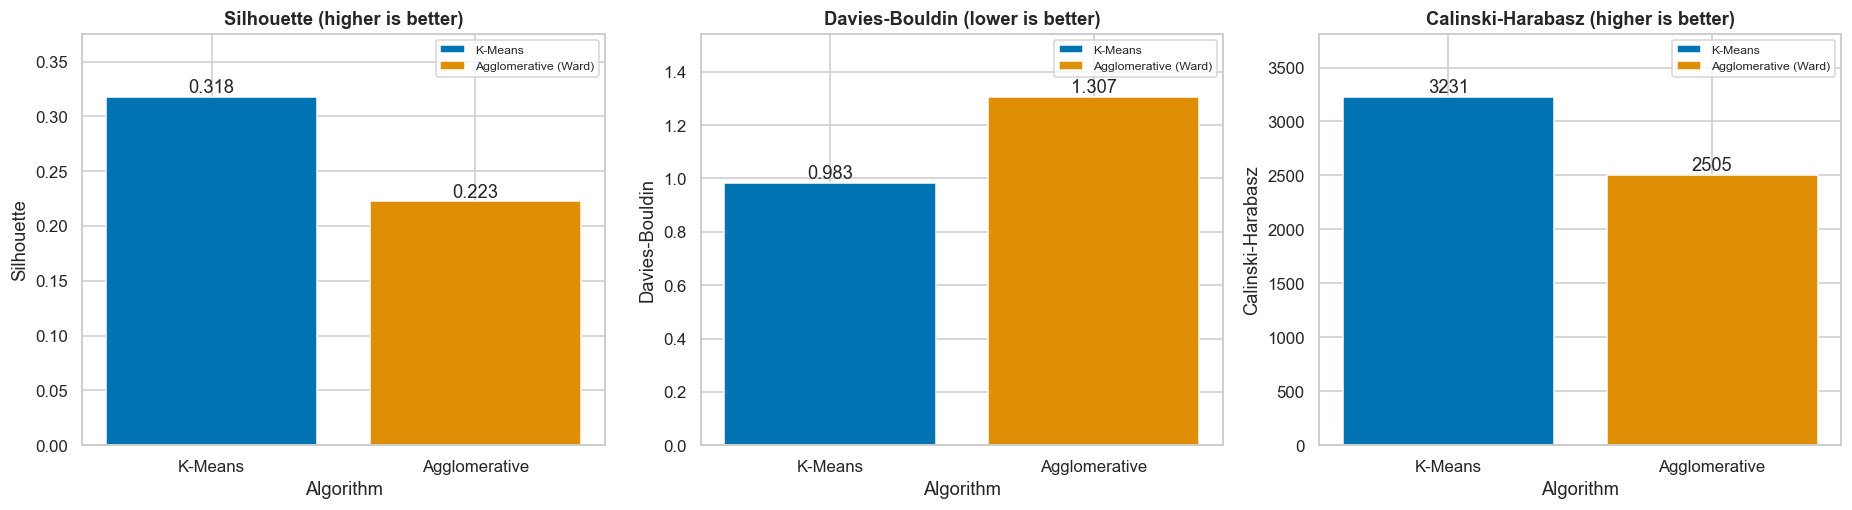

In [21]:
eval_df = pd.DataFrame([
    {'Algorithm': f'K-Means (k={OPTIMAL_K}, k-means++)', **cluster_metrics(X, km_labels),
     'Cluster sizes': ', '.join(map(str, np.bincount(km_labels)))},
    {'Algorithm': f'Agglomerative (k={OPTIMAL_K}, Ward)', **cluster_metrics(X, agg_labels),
     'Cluster sizes': ', '.join(map(str, np.bincount(agg_labels)))},
]).set_index('Algorithm')
display(eval_df.style.format({'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}', 'Calinski-Harabasz': '{:,.1f}'})
        .set_caption('Clustering evaluation on the standardised log-RFM matrix'))
eval_df.to_csv(REPORTS_DIR / 'clustering_comparison.csv', float_format='%.4f')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (m, better) in zip(axes, [('Silhouette', 'higher'), ('Davies-Bouldin', 'lower'), ('Calinski-Harabasz', 'higher')]):
    bars = ax.bar(['K-Means', 'Agglomerative'], eval_df[m], color=[PALETTE[0], PALETTE[1]],
                  label=['K-Means', 'Agglomerative (Ward)'])
    ax.bar_label(bars, fmt='%.3f' if m != 'Calinski-Harabasz' else '%.0f')
    ax.set(title=f'{m} ({better} is better)', xlabel='Algorithm', ylabel=m, ylim=(0, eval_df[m].max() * 1.18))
    ax.legend(fontsize=8)
plt.tight_layout(); save_fig(fig, 'metrics_comparison'); plt.show()

**📝 Observations — evaluation metrics**
- **K-Means is better on all three metrics**: Silhouette 0.318 vs 0.223 (higher is better), Davies–Bouldin 0.983 vs 1.307 (lower is better), and Calinski–Harabasz 3,231 vs 2,505 (higher is better).
- This is expected. K-Means directly and iteratively optimises within-cluster variance and can move any customer between clusters until convergence. Agglomerative clustering is *greedy*: once two groups are merged they can never be split again, so early merges that are locally optimal can be globally sub-optimal.
- Agglomerative clustering's strengths are elsewhere: it needs no random initialisation, it is deterministic, and the dendrogram shows the **whole hierarchy** (useful for choosing k and for nested segments). The cost is O(n²) memory, which limits it to small datasets like this one (4,334 customers).

### 6.1 Do the two algorithms agree? Is K-Means stable?

Agreement K-Means vs Agglomerative → ARI = 0.422 | NMI = 0.534


K-Means stability over 20 single-start seeds → ARI mean 0.911 (min 0.775)


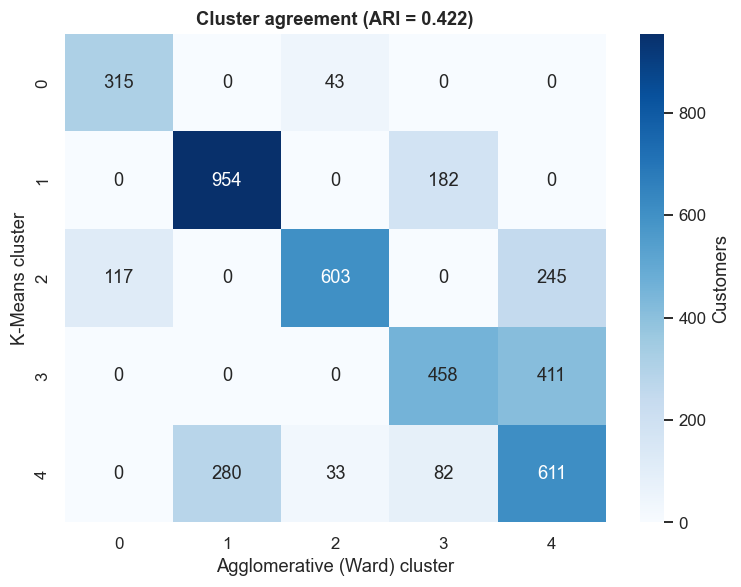

In [22]:
ari = adjusted_rand_score(km_labels, agg_labels)
nmi = normalized_mutual_info_score(km_labels, agg_labels)
print(f'Agreement K-Means vs Agglomerative → ARI = {ari:.3f} | NMI = {nmi:.3f}')

seed_ari = [adjusted_rand_score(km_labels, KMeans(OPTIMAL_K, n_init=1, random_state=s).fit_predict(X))
            for s in range(20)]
print(f'K-Means stability over 20 single-start seeds → ARI mean {np.mean(seed_ari):.3f} (min {np.min(seed_ari):.3f})')

fig, ax = plt.subplots(figsize=(7, 5.5))
ct = pd.crosstab(pd.Series(km_labels, name='K-Means cluster'), pd.Series(agg_labels, name='Agglomerative cluster'))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Customers'}, ax=ax)
ax.set(title=f'Cluster agreement (ARI = {ari:.3f})', xlabel='Agglomerative (Ward) cluster', ylabel='K-Means cluster')
plt.tight_layout(); save_fig(fig, 'agreement'); plt.show()

**📝 Observations — agreement and stability**
- **Adjusted Rand Index = 0.42, NMI = 0.53** between the two algorithms: clearly better than chance (ARI 0) but far from identical (ARI 1). The cross-tab shows that both algorithms agree on the extremes: 315 of the 358 K-Means champions and 954 of the 1,136 lost customers fall in a single Ward cluster. They disagree mainly on the boundaries between the three middle segments, which lie in a continuous region of RFM space.
- **Stability:** 20 K-Means runs with a *single* random start each agree with the final model at ARI 0.91 on average (minimum 0.78). The final model keeps the best of 20 starts (`n_init = 20`), so the reported solution is the stable one rather than a lucky initialisation.

---
## 7 · Cluster visualisation

### 7.1 PCA — two principal components

Explained variance ratio: [0.7515 0.1871] → total 93.9%


,PC1,PC2
Recency,-0.513,0.849
Frequency,0.618,0.262
Monetary,0.597,0.458


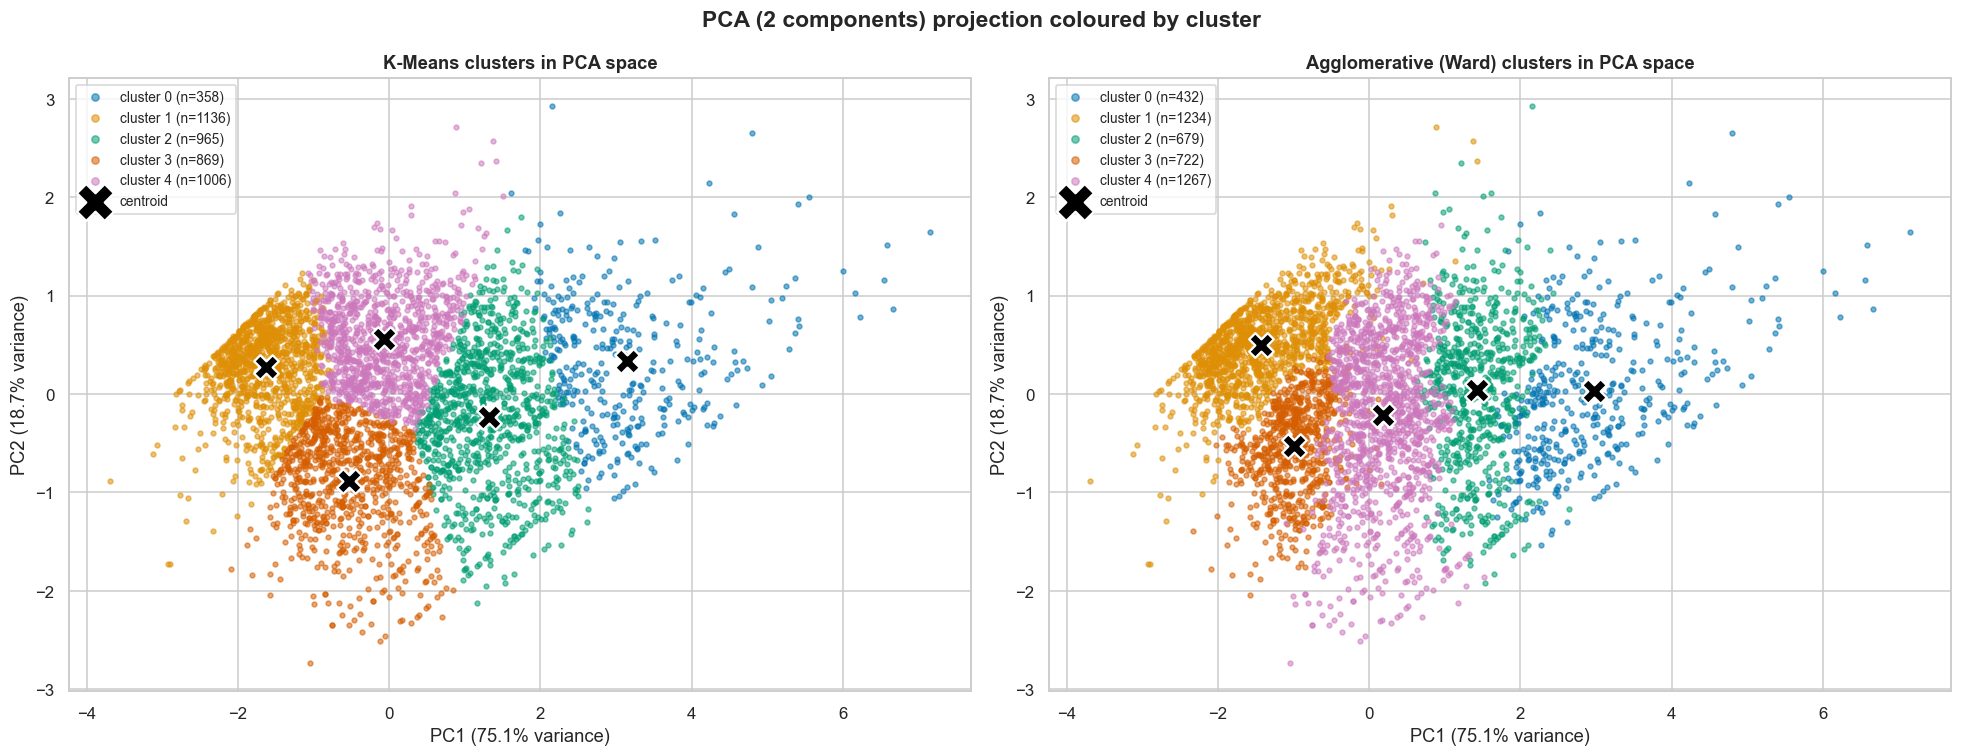

In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)
loadings = pd.DataFrame(pca.components_.T, index=RFM, columns=['PC1', 'PC2']).round(3)
print('Explained variance ratio:', pca.explained_variance_ratio_.round(4),
      f'→ total {pca.explained_variance_ratio_.sum():.1%}')
display(loadings)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, labels, model, name in [(axes[0], km_labels, kmeans, 'K-Means'), (axes[1], agg_labels, None, 'Agglomerative (Ward)')]:
    for c in range(OPTIMAL_K):
        m = labels == c
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=0.55, color=PALETTE[c], label=f'cluster {c} (n={m.sum()})')
    cent = pca.transform(model.cluster_centers_) if model is not None else \
        np.vstack([X_pca[labels == c].mean(0) for c in range(OPTIMAL_K)])
    ax.scatter(cent[:, 0], cent[:, 1], marker='X', s=260, c='black', edgecolor='white', lw=1.5, label='centroid')
    ax.set(title=f'{name} clusters in PCA space', xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)',
           ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
    ax.legend(markerscale=1.5, fontsize=9)
fig.suptitle('PCA (2 components) projection coloured by cluster', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'pca_clusters'); plt.show()

**📝 Observations — PCA projection**
- Two principal components keep **93.9 % of the variance** (PC1 75.2 %, PC2 18.7 %), so this 2-D picture is a faithful view of the 3-D RFM space.
- **PC1 ≈ overall customer value:** large positive loadings on Frequency (0.62) and Monetary (0.60), negative on Recency (−0.51). **PC2 ≈ recency vs spend:** it is dominated by Recency (0.85).
- K-Means produces **five clean, contiguous bands along PC1** (from lost customers on the left to champions on the right), separated along PC2 by how recently customers bought. The black ✕ centroids are well apart.
- The Ward clusters cover the same space but with more overlapping, irregular boundaries, which matches its lower silhouette.

### 7.2 t-SNE — non-linear 2-D embedding

t-SNE finished in 142s


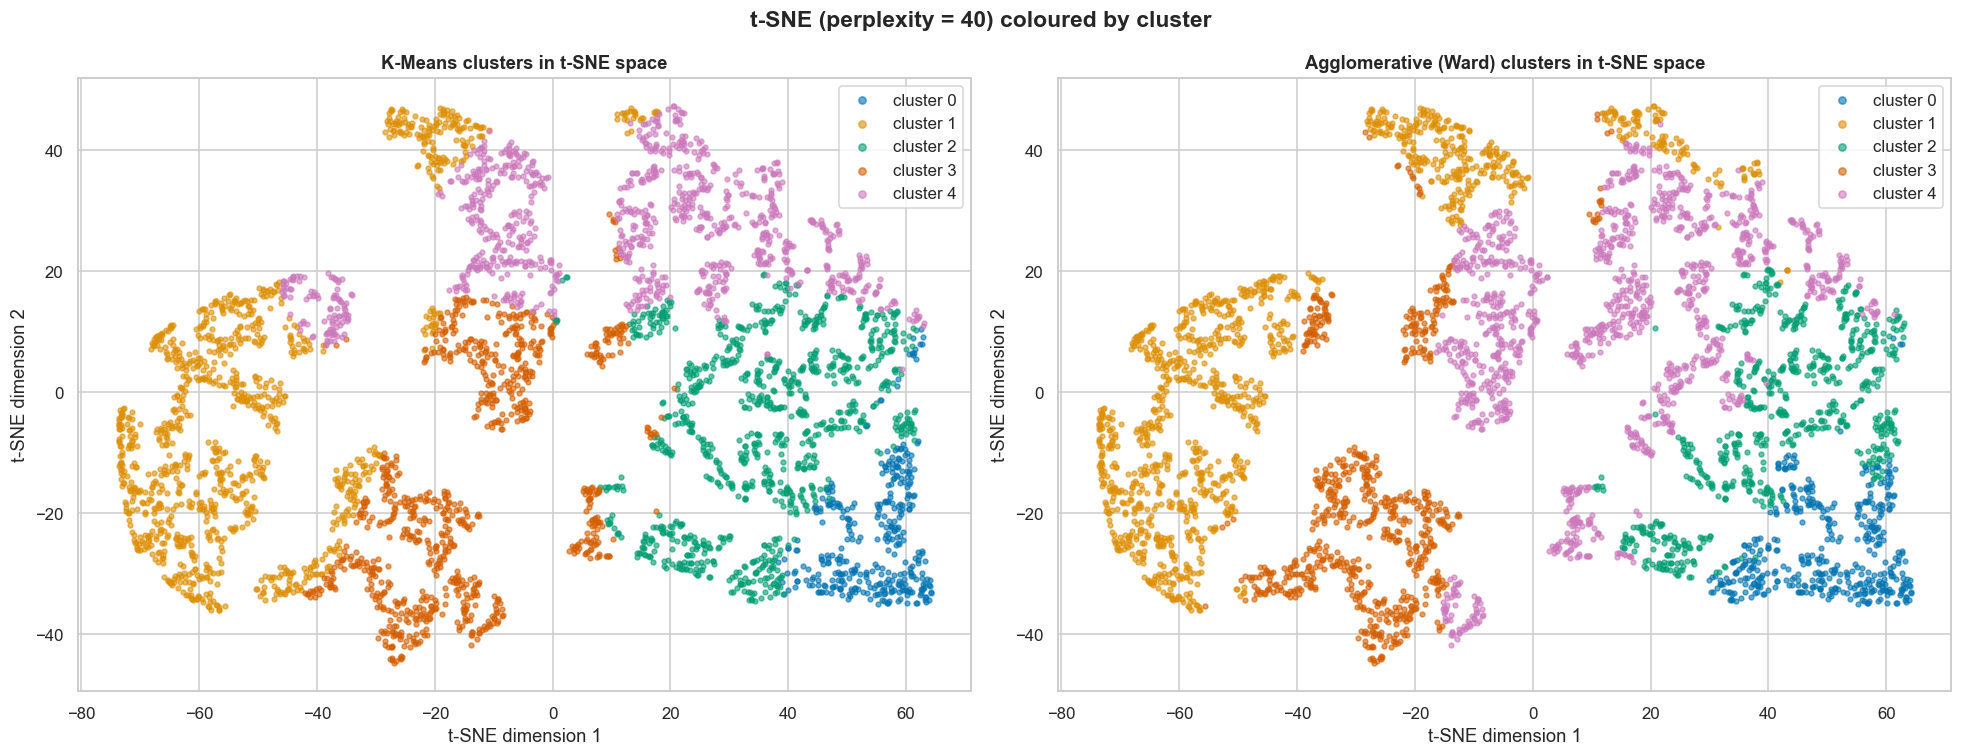

In [24]:
t0 = time.time()
X_tsne = TSNE(n_components=2, perplexity=40, init='pca', learning_rate='auto',
              random_state=RANDOM_STATE).fit_transform(X)
print(f't-SNE finished in {time.time() - t0:.0f}s')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, labels, name in [(axes[0], km_labels, 'K-Means'), (axes[1], agg_labels, 'Agglomerative (Ward)')]:
    for c in range(OPTIMAL_K):
        m = labels == c
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=10, alpha=0.6, color=PALETTE[c], label=f'cluster {c}')
    ax.set(title=f'{name} clusters in t-SNE space', xlabel='t-SNE dimension 1', ylabel='t-SNE dimension 2')
    ax.legend(markerscale=1.5)
fig.suptitle('t-SNE (perplexity = 40) coloured by cluster', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'tsne_clusters'); plt.show()

**📝 Observations — t-SNE projection**
- t-SNE (non-linear, preserves local neighbourhoods) shows **islands** of customers rather than a single cloud. Customers with exactly the same small Frequency values (1, 2, 3 orders) form separate ribbons, because Frequency is a discrete count.
- For K-Means, each segment occupies its own coherent region, and the champions (cluster 0) form a compact group at the edge of the high-value region. The same layout coloured by the Ward labels shows more mixed regions, again matching the metric comparison.
- t-SNE distances and axis values have no direct meaning, and the picture changes with `perplexity`. It is used **only for visual confirmation**, never for fitting or measuring clusters.

---
## 8 · Cluster profiling, naming and business actions

Profiles use the **original units** (days, invoices, £) so that they can be read by a marketing team.

In [25]:
seg = rfm.assign(Cluster=km_labels)
profile = seg.groupby('Cluster').agg(
    Customers=('Recency', 'size'),
    Recency_median=('Recency', 'median'), Frequency_median=('Frequency', 'median'),
    Monetary_median=('Monetary', 'median'), Monetary_total=('Monetary', 'sum'),
    AvgBasket_median=('AvgBasketValue', 'median'), Tenure_median=('Tenure', 'median'),
    UniqueProducts_median=('UniqueProducts', 'median'),
    UK_share=('Country', lambda s: (s == 'United Kingdom').mean() * 100))
profile['Customer_%'] = profile['Customers'] / profile['Customers'].sum() * 100
profile['Revenue_%'] = profile['Monetary_total'] / profile['Monetary_total'].sum() * 100


def name_segment(r, med):
    """Rule-based naming from the cluster's median RFM relative to the whole customer base."""
    recent = r['Recency_median'] <= med['Recency']
    valuable = (r['Frequency_median'] > med['Frequency']) and (r['Monetary_median'] > med['Monetary'])
    if recent and r['Frequency_median'] >= 4 * med['Frequency'] and r['Monetary_median'] >= 4 * med['Monetary']:
        return 'Champions'
    if recent and valuable:
        return 'Loyal Customers'
    if recent:
        return 'New / Promising'
    if valuable or r['Monetary_median'] > med['Monetary']:
        return 'At-Risk'
    return 'Lost / Hibernating'


def unique_names(names, value):
    """If two clusters get the same rule-based name, the more valuable one keeps it and the other gets a tier suffix."""
    out, seen = {}, {}
    for c in value.sort_values(ascending=False).index:
        n = names[c]
        seen[n] = seen.get(n, 0) + 1
        out[c] = n if seen[n] == 1 else f'{n} (tier {seen[n]})'
    return pd.Series(out).reindex(names.index)


overall_med = rfm[RFM].median()
profile['Segment'] = unique_names(profile.apply(name_segment, axis=1, med=overall_med), profile['Monetary_median'])
display(profile.round(1))
print('Whole customer base medians:', overall_med.round(1).to_dict())

,Customers,Recency_median,Frequency_median,Monetary_median,Monetary_total,AvgBasket_median,Tenure_median,UniqueProducts_median,UK_share,Customer_%,Revenue_%,Segment
Cluster,,,,,,,,,,,,
0,358,8.0,15.0,5795.0,4703439.8,397.1,366.0,148.0,88.8,8.3,53.8,Champions
1,1136,219.0,1.0,239.4,305918.6,197.8,244.0,14.0,92.0,26.2,3.5,Lost / Hibernating
2,965,17.0,5.0,1717.4,1984297.1,320.3,284.0,79.0,90.5,22.3,22.7,Loyal Customers
3,869,26.0,1.0,335.9,320858.8,215.1,51.0,24.0,92.2,20.1,3.7,New / Promising
4,1006,83.0,3.0,980.7,1422713.4,357.3,267.0,44.5,87.4,23.2,16.3,At-Risk


Whole customer base medians: {'Recency': 51.0, 'Frequency': 2.0, 'Monetary': 662.6}


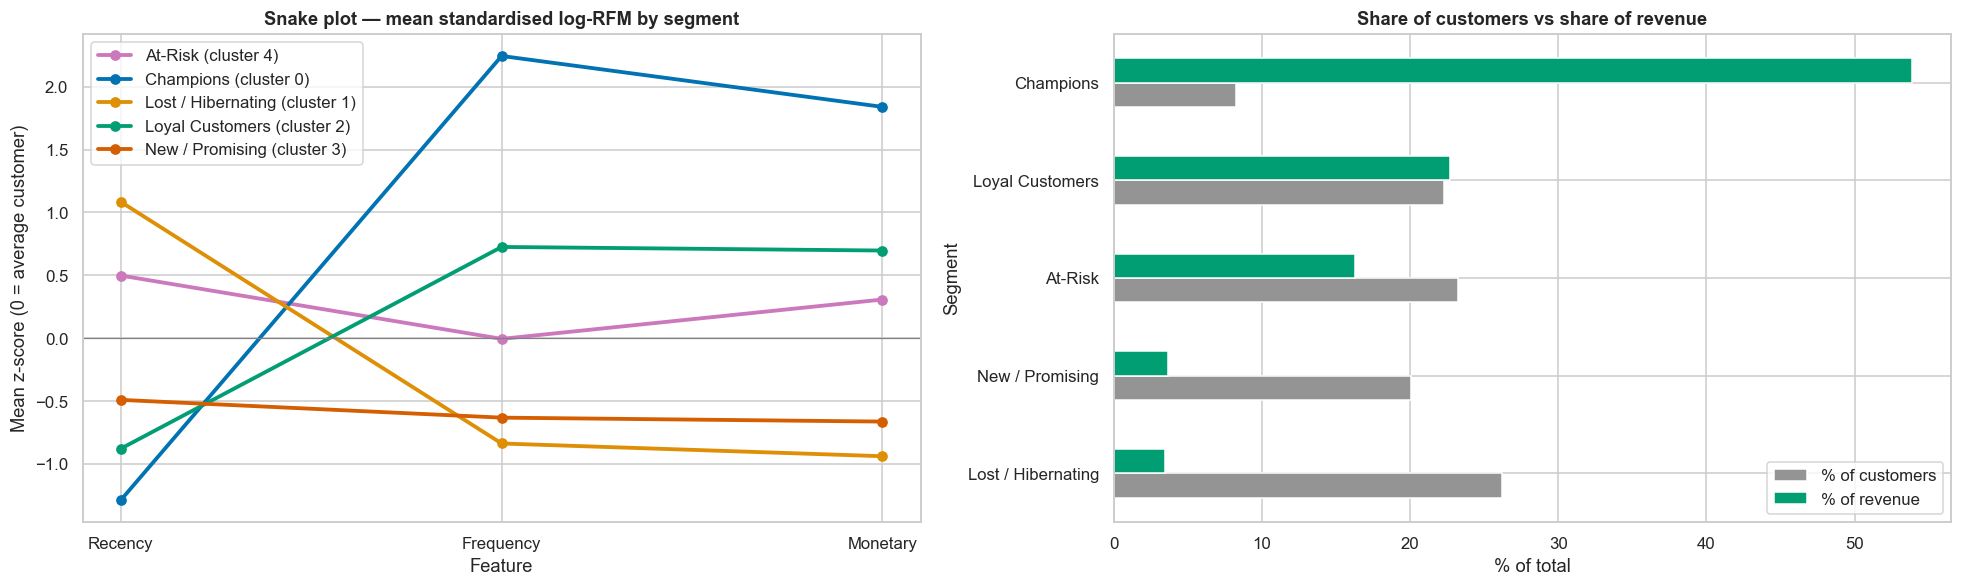

In [26]:
# Snake plot: mean standardised log-RFM per cluster
snake = X_df.assign(Segment=profile['Segment'].reindex(km_labels).values).groupby('Segment')[RFM].mean()
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
seg_to_cluster = {v: k for k, v in profile['Segment'].items()}      # same colours as the cluster plots
for segname, row in snake.iterrows():
    c = seg_to_cluster[segname]
    axes[0].plot(RFM, row.values, marker='o', lw=2.5, color=PALETTE[c], label=f'{segname} (cluster {c})')
axes[0].axhline(0, color='grey', lw=0.8)
axes[0].set(title='Snake plot — mean standardised log-RFM by segment', xlabel='Feature',
            ylabel='Mean z-score (0 = average customer)')
axes[0].legend()

share = profile.set_index('Segment')[['Customer_%', 'Revenue_%']].sort_values('Revenue_%')
share.plot.barh(ax=axes[1], color=[PALETTE[7], PALETTE[2]])
axes[1].set(title='Share of customers vs share of revenue', xlabel='% of total', ylabel='Segment')
axes[1].legend(['% of customers', '% of revenue'])
plt.tight_layout(); save_fig(fig, 'segment_profiles'); plt.show()

**📝 Observations — segment profiles (K-Means, medians)**

| Segment | Customers | Recency (days) | Orders | Spend (£) | Share of revenue |
|---------|-----------|----------------|--------|-----------|------------------|
| **Champions** | 358 (8.3 %) | 8 | 15 | 5,795 | **53.8 %** |
| **Loyal Customers** | 965 (22.3 %) | 17 | 5 | 1,717 | 22.7 % |
| **At-Risk** | 1,006 (23.2 %) | 83 | 3 | 981 | 16.3 % |
| **New / Promising** | 869 (20.1 %) | 26 | 1 | 336 | 3.7 % |
| **Lost / Hibernating** | 1,136 (26.2 %) | 219 | 1 | 239 | 3.5 % |

- The revenue distribution follows a strong **Pareto pattern**: the top 30 % of customers (Champions + Loyal) generate **76.5 % of revenue**.
- **New / Promising** customers have a median tenure of only 51 days (first purchase recently) against 366 days for Champions. They are genuinely *new*, not just low-value, which is a different marketing problem.
- **At-Risk** customers used to buy regularly (median 3 orders, about £1,000) but have not ordered for almost 3 months. They are the most valuable group to win back.
- The snake plot makes each segment's "shape" visible. Champions are far above average on Frequency and Monetary and far below on Recency. Lost customers are the mirror image.

### 8.1 Post-hoc sanity check with classic RFM scores (not used for fitting)
Marketing teams often score customers 1–5 on each of R, F and M by quintile (5 = best). These scores were **not** used to
build the clusters; if our clusters are meaningful, their RFM scores should be clearly ordered.

,R,F,M,RFM_score
Segment,,,,
Champions,4.62,4.99,4.99,14.61
Loyal Customers,4.29,4.35,4.23,12.87
At-Risk,2.27,3.22,3.61,9.10
New / Promising,3.83,2.14,1.95,7.91
Lost / Hibernating,1.41,1.68,1.60,4.69


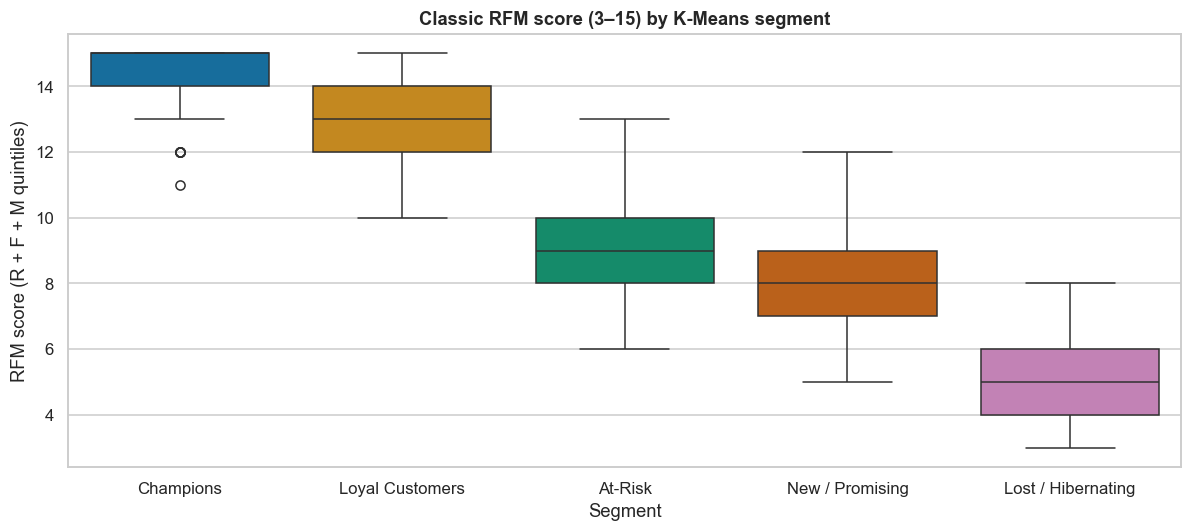

In [27]:
scores = pd.DataFrame({
    'R': pd.qcut(rfm['Recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int),
    'F': pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int),
    'M': pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int),
}, index=rfm.index)
scores['RFM_score'] = scores[['R', 'F', 'M']].sum(axis=1)
scores['Segment'] = profile['Segment'].reindex(km_labels).values
order = scores.groupby('Segment')['RFM_score'].mean().sort_values(ascending=False).index

display(scores.groupby('Segment')[['R', 'F', 'M', 'RFM_score']].mean().loc[order].round(2))
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=scores, x='Segment', y='RFM_score', order=order, hue='Segment', hue_order=order,
            palette='colorblind', legend=False, ax=ax)
ax.set(title='Classic RFM score (3–15) by K-Means segment', xlabel='Segment', ylabel='RFM score (R + F + M quintiles)')
plt.tight_layout(); save_fig(fig, 'rfm_score_check'); plt.show()

**📝 Observations — post-hoc check against classic RFM scores**
- The quintile-based RFM score was **never used to fit the clusters**, yet the segments are perfectly ordered by it: **Champions 14.6 > Loyal 12.9 > At-Risk 9.1 > New 7.9 > Lost 4.7** (out of 15).
- The per-letter scores explain the names. *New / Promising* has a good R score (3.8) but low F and M. *At-Risk* has a poor R score (2.3) but above-average F and M.
- This independent business heuristic agreeing with the unsupervised result is strong evidence that the clusters are meaningful, and not an artefact of the algorithm.

### 8.2 Recommended actions per segment

| Segment | Goal | Suggested action |
|---------|------|------------------|
| **Champions** | retain, protect revenue | VIP tier, early access to new ranges, account manager for the largest wholesalers; avoid unnecessary discounts |
| **Loyal Customers** | grow basket and frequency | bundles, volume pricing, personalised cross-sell from past categories |
| **At-Risk** | win back before they lapse | personalised "we miss you" offer on their usual products; ask for feedback |
| **New / Promising** | secure the second order | onboarding sequence, time-limited second-order incentive, best-seller recommendations |
| **Lost / Hibernating** | reactivate cheaply or let go | seasonal newsletter before Q4 only; do not spend heavily |

---
## 9 · Saving the model and results

The deployable model is a scikit-learn `Pipeline` — `log1p → StandardScaler → KMeans` — so a new customer's raw RFM
values can be segmented with one `predict()` call. The PCA projection and segment names are stored alongside it for
the GUI.

In [28]:
cluster_pipeline = Pipeline([
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=OPTIMAL_K, init='k-means++', n_init=20, random_state=RANDOM_STATE)),
]).fit(rfm[RFM])
assert np.array_equal(cluster_pipeline.predict(rfm[RFM]), km_labels), 'pipeline must reproduce notebook labels'

segment_names = profile['Segment'].to_dict()
sample = rfm[RFM].assign(Cluster=km_labels, PC1=X_pca[:, 0], PC2=X_pca[:, 1]).sample(1500, random_state=RANDOM_STATE)
artifact = {
    'pipeline': cluster_pipeline,
    'pca': pca,
    'features': RFM,
    'segment_names': {int(k): v for k, v in segment_names.items()},
    'profile': profile.round(2).reset_index().to_dict('records'),
    'sample_points': sample.round(3).reset_index().to_dict('records'),
}
seg_name = profile['Segment']
artifact['customers'] = (rfm[RFM].assign(KMeans=km_labels, Agglomerative=agg_labels,
                                         Segment=seg_name.reindex(km_labels).values,
                                         PC1=X_pca[:, 0], PC2=X_pca[:, 1], TSNE1=X_tsne[:, 0], TSNE2=X_tsne[:, 1])
                         .round(3).reset_index().to_dict('records'))
joblib.dump(artifact, MODELS_DIR / 'clustering_kmeans.pkl')

# Small EDA summaries for the GUI (the 23 MB Excel file is too heavy to load in a web app)
eda = {
    'cleaning_log': log.to_dict('records'),
    'monthly': monthly.reset_index(names='Month').round(2).to_dict('records'),
    'countries': by_country.head(15).reset_index().round(2).to_dict('records'),
    'weekday_hour': {'index': heat.index.tolist(), 'columns': [int(c) for c in heat.columns], 'values': heat.values.tolist()},
    'top_products': (tx.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)
                     .round(2).reset_index().to_dict('records')),
    'quality': quality.reset_index(names='Issue').to_dict('records'),
}
(REPORTS_DIR / 'clustering_eda.json').write_text(json.dumps(eda, indent=2, default=str))

summary = {
    'track': 'clustering', 'dataset': 'Online Retail (UCI)',
    'n_transactions_raw': int(len(raw)), 'n_transactions_clean': int(len(tx)), 'n_customers': int(len(rfm)),
    'snapshot_date': f'{SNAPSHOT:%Y-%m-%d}', 'features': RFM, 'transform': 'log1p + StandardScaler',
    'k': int(OPTIMAL_K), 'k_selection': sweep.round(4).reset_index().to_dict('records'),
    'metrics': {k: {m: round(float(v), 4) for m, v in r.items() if m != 'Cluster sizes'}
                for k, r in eval_df.to_dict('index').items()},
    'linkage_comparison': link_df.drop(columns='Cluster sizes').round(4).reset_index().to_dict('records'),
    'agreement': {'ARI': round(float(ari), 4), 'NMI': round(float(nmi), 4)},
    'pca_explained_variance': [round(float(v), 4) for v in pca.explained_variance_ratio_],
    'segments': profile.round(2).reset_index().to_dict('records'),
    'random_state': RANDOM_STATE,
}
(REPORTS_DIR / 'clustering_results.json').write_text(json.dumps(summary, indent=2, default=str))
print('Saved models/clustering_kmeans.pkl, reports/clustering_results.json, reports/clustering_comparison.csv')

Saved models/clustering_kmeans.pkl, reports/clustering_results.json, reports/clustering_comparison.csv


---
## 10 · Conclusions

**Final model:** **K-Means, k = 5**, on log-transformed and standardised RFM features of 4,334 customers. Silhouette **0.318**, Davies–Bouldin **0.983**, Calinski–Harabasz **3,231**, better than Ward agglomerative clustering on all three metrics (0.223 / 1.307 / 2,505).

**Key findings**
1. **Preprocessing decides the result.** Removing cancellations, non-product charges and anonymous lines, then log-transforming heavily skewed RFM values, is what makes distance-based clustering meaningful here.
2. **k = 5 balances statistics and usefulness.** It sits at the elbow and at a Davies–Bouldin minimum, and it is the first k that separates the *Champions* (8 % of customers, 54 % of revenue) from ordinary loyal buyers.
3. **K-Means beats Ward on every internal metric**, because it optimises the variance objective globally while Ward merges greedily. The dendrogram is still valuable for seeing the hierarchy (2–3 broad groups, 5 useful sub-groups).
4. **Metrics can mislead.** Single and average linkage have the best silhouette but are useless (one cluster holds 62–100 % of customers). Cluster sizes must always be checked.
5. **The segments are real.** They are perfectly ordered by an independent RFM score, and their business profiles are distinct and actionable.

**Limitations:** one year of data from one retailer; RFM ignores *what* is bought (product categories) and seasonality; segments should be refreshed regularly because customers move between them.

**References:** Chen, D., Sain, S.L. & Guo, K. (2012). *Data mining for the online retail industry: a case study of RFM model-based customer segmentation using data mining.* Journal of Database Marketing & Customer Strategy Management 19, 197–208 · UCI ML Repository, dataset #352 · scikit-learn 1.8 user guide (clustering, clustering performance evaluation) · SciPy `scipy.cluster.hierarchy` documentation.